<a id="top"></a>

# Netflix Content Analytics: End-to-End Data Analysis with Python

**Auspify Technologies · Data Analysis Using Python Internship · Tasks 1–6**
**Prepared by:** Furqaan

---

## Executive Overview

This notebook completes **all six** tasks of the Auspify *Data Analysis Using Python* task list on a single Netflix catalog dataset. It is written as one continuous, reproducible analysis: raw data goes in, a validated clean dataset is produced in Task 1, and every later task builds on that clean dataset.

| # | Level | Task | What it delivers |
|---|-------|------|------------------|
| [1](#task1) | Easy | Data Cleaning & Preparation | Validated, analysis-ready dataset + cleaning log + export |
| [2](#task2) | Easy | Content Type Analysis Dashboard | Movies vs TV Shows distribution, proportions, summary |
| [3](#task3) | Medium | Country-Wise Content Analysis | Country rankings, concentration, geographic map, insights |
| [4](#task4) | Medium | Trend Analysis by Release Year | Yearly trends, growth/decline phases, seasonality |
| [5](#task5) | Advanced | Content Rating & Genre Analysis | Audience segmentation, interactive visuals, statistical tests |
| [6](#task6) | Advanced | Business Insights Report | EDA, three dashboards, recommendations, executive summary |

### Notebook conventions
* **Every number in the written findings is computed from the data** and inserted programmatically, so text and charts can never drift apart.
* **Data-quality decisions are explicit.** Each cleaning rule states what was found, what was done, and why.
* **Outputs** (cleaned CSV, all figures, summary files) are written to the `data/outputs/` folder next to this notebook.

### Requirements
`python >= 3.9` · `pandas` · `numpy` · `matplotlib` · `seaborn` · `plotly` · `scipy`
Install with: ` install pandas numpy matplotlib seaborn plotly scipy`

### Data dictionary (raw file)

| Column | Description |
|--------|-------------|
| `show_id` | Unique identifier of the title |
| `type` | Content type: `Movie` or `TV Show` |
| `title` | Title of the content |
| `director` | Director name(s); missing values are stored as the text `Not Given` |
| `country` | Country of production; missing values are stored as the text `Not Given` |
| `date_added` | Date the title was added to the platform (`m/d/yyyy` text) |
| `release_year` | Original release year |
| `rating` | Maturity rating (e.g. `TV-MA`, `PG-13`) |
| `duration` | Runtime in minutes for movies, number of seasons for TV shows (text) |
| `listed_in` | Comma-separated genre / category tags |

## Step 1 · Import the dataset

<a id="task2"></a>

---

# Task 2 · Content Type Analysis Dashboard  `Easy`

**Goal:** analyse the distribution of Movies and TV Shows on Netflix.

| Step | Activity |
|------|----------|
| 1 | Load the cleaned dataset |
| 2 | Calculate the total number of Movies and TV Shows |
| 3 | Create visualisations of the content distribution |
| 4 | Compare content proportions |
| 5 | Summarise key findings |

## Step 1 · Load the cleaned dataset

In [23]:
def load_clean(path: Path = CLEAN_PATH) -> pd.DataFrame:
    """Load the Task 1 export and restore ordered categorical types."""
    data = pd.read_csv(path, parse_dates=["date_added"], keep_default_na=False, na_values=[""])
    data["rating"] = pd.Categorical(data["rating"], categories=[r for r in RATING_ORDER if r in set(data["rating"])], ordered=True)
    data["audience_group"] = pd.Categorical(data["audience_group"], categories=AUDIENCE_ORDER, ordered=True)
    return data


df = load_clean()
print(f"Cleaned dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")

# Snapshot cut-off: the last month in the data is incomplete, so the final year is a partial year.
LAST_DATE = df["date_added"].max()
PARTIAL_YEAR = LAST_DATE.year if LAST_DATE < pd.Timestamp(LAST_DATE.year, 12, 15) else None
print(f"Catalog snapshot runs to {LAST_DATE:%d %B %Y}; {PARTIAL_YEAR} is a PARTIAL year and is flagged in charts.")
display(df.head(3))

Cleaned dataset loaded: 8,786 rows x 21 columns
Catalog snapshot runs to 25 September 2021; 2021 is a PARTIAL year and is flagged in charts.


,show_id,type,title,director,country,country_reliable,country_suspect,date_added,year_added,month_added,...,lag_years,rating,audience_group,maturity_level,duration_min,n_seasons,listed_in,n_genres,title_date_artifact,added_before_release
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,United States,False,2021-09-25,2021,9,...,1,PG-13,Teens,3.0,90.0,NaN,Documentaries,1,False,False
1,s3,TV Show,Ganglands,Julien Leclercq,France,France,False,2021-09-24,2021,9,...,0,TV-MA,Adults,4.0,NaN,1.0,"Crime TV Shows, International TV Shows, TV Act...",3,False,False
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,United States,False,2021-09-24,2021,9,...,0,TV-MA,Adults,4.0,NaN,1.0,"TV Dramas, TV Horror, TV Mysteries",3,False,False


## Step 2 · Total Movies and TV Shows

In [24]:
type_counts = df["type"].value_counts().reindex(TYPE_ORDER)
total_titles = int(type_counts.sum())
movie_n, tv_n = int(type_counts["Movie"]), int(type_counts["TV Show"])
movies_per_tv = movie_n / tv_n

summary = pd.DataFrame({"Titles": type_counts, "Share of catalog": type_counts / total_titles})
summary.loc["Total"] = [total_titles, 1.0]
display(summary.style.format({"Titles": "{:,.0f}", "Share of catalog": "{:.1%}"}).set_caption("Catalog size by content type"))
print(f"For every TV show there are {movies_per_tv:.2f} movies.")

,Titles,Share of catalog
type,,
Movie,"6,123",69.7%
TV Show,"2,663",30.3%
Total,"8,786",100.0%


For every TV show there are 2.30 movies.


## Step 3 · Content distribution visualisations

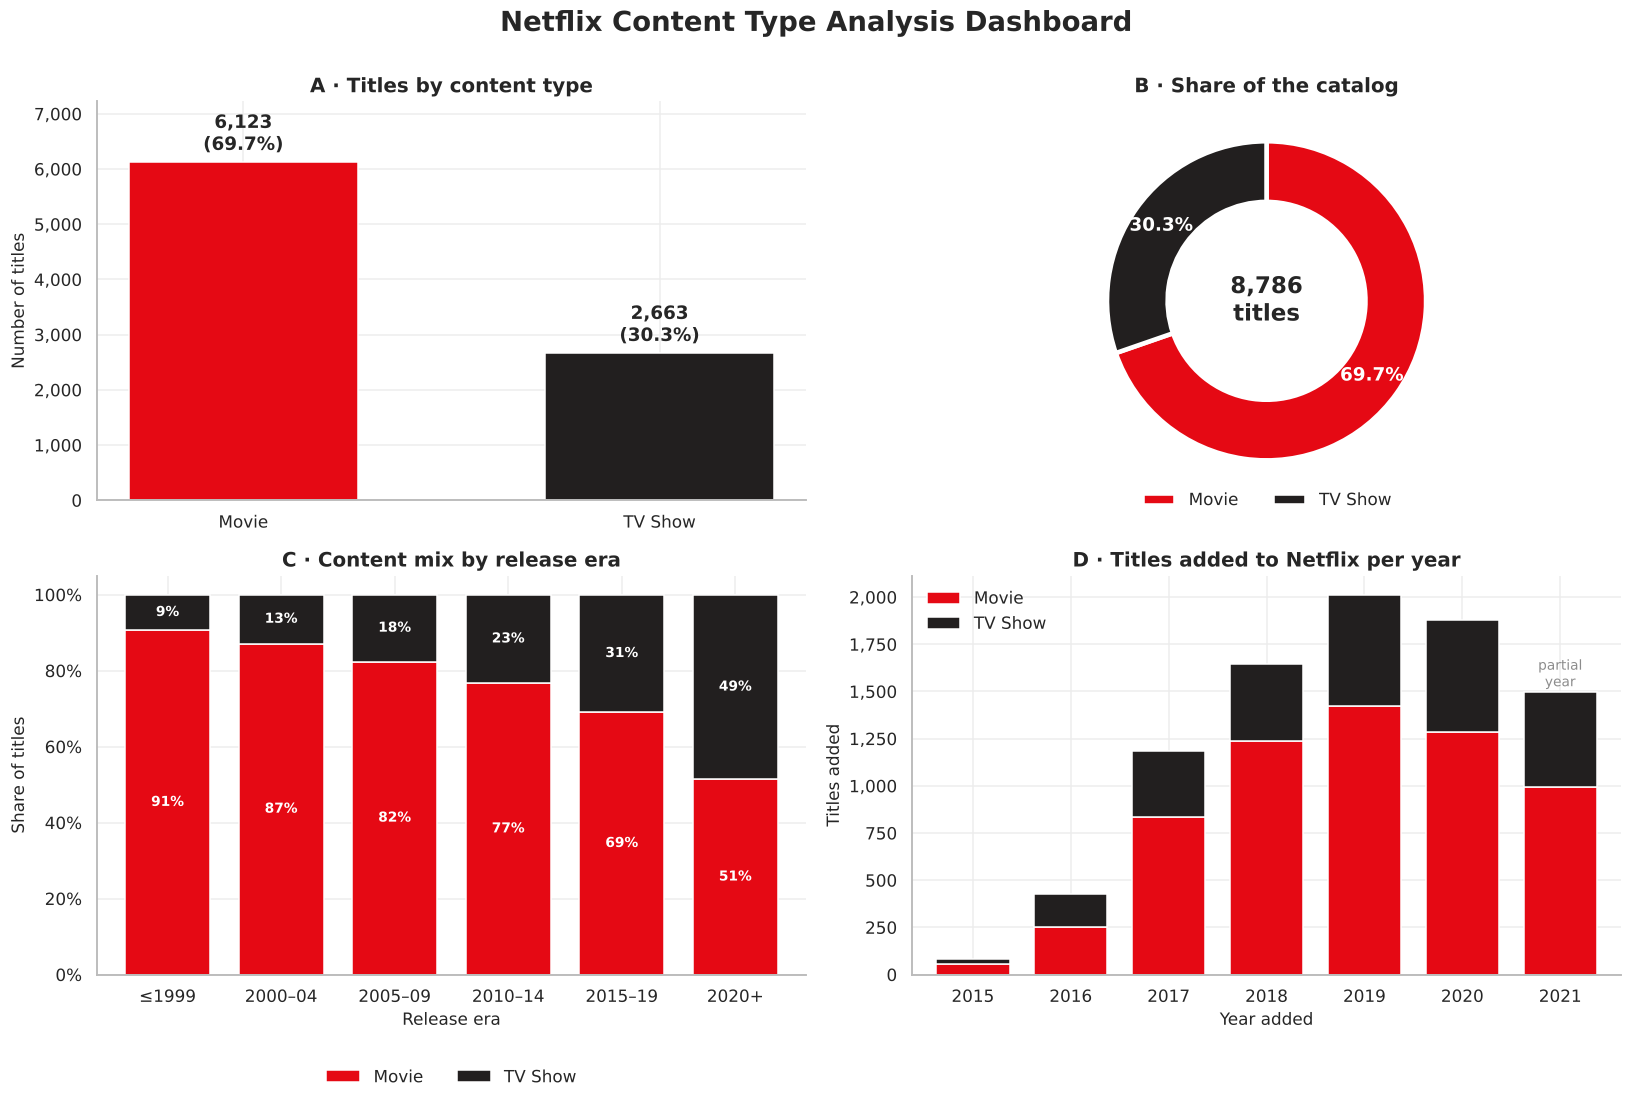

In [25]:
# Panel data -----------------------------------------------------------------------
ERA_BINS = [-np.inf, 1999, 2004, 2009, 2014, 2019, np.inf]
ERA_LABELS = ["≤1999", "2000–04", "2005–09", "2010–14", "2015–19", "2020+"]
df["release_era"] = pd.cut(df["release_year"], bins=ERA_BINS, labels=ERA_LABELS)

era_share = pd.crosstab(df["release_era"], df["type"], normalize="index")[TYPE_ORDER]
added = pd.crosstab(df["year_added"], df["type"])[TYPE_ORDER]
added = added[added.index >= 2015]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("Netflix Content Type Analysis Dashboard", fontsize=18, fontweight="bold", y=1.0)

# (A) counts
ax = axes[0, 0]
bars = ax.bar(TYPE_ORDER, type_counts.values, color=[TYPE_COLORS[t] for t in TYPE_ORDER], width=0.55)
ax.bar_label(bars, labels=[f"{v:,}\n({v / total_titles:.1%})" for v in type_counts.values], padding=4, fontweight="bold")
ax.set(title="A · Titles by content type", ylabel="Number of titles", ylim=(0, type_counts.max() * 1.18))
thousands(ax)

# (B) donut
ax = axes[0, 1]
ax.pie(type_counts.values, colors=[TYPE_COLORS[t] for t in TYPE_ORDER], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.38, edgecolor="white", linewidth=3),
       autopct=lambda p: f"{p:.1f}%", pctdistance=0.81, textprops=dict(color="white", fontweight="bold", fontsize=12))
ax.text(0, 0, f"{total_titles:,}\ntitles", ha="center", va="center", fontsize=15, fontweight="bold")
ax.legend(TYPE_ORDER, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06))
ax.set_title("B · Share of the catalog")

# (C) type mix by release era
ax = axes[1, 0]
era_share.plot(kind="bar", stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in TYPE_ORDER], width=0.75, legend=False)
for container, t in zip(ax.containers, TYPE_ORDER):
    ax.bar_label(container, labels=[f"{v:.0%}" for v in era_share[t]], label_type="center", color="white", fontsize=9, fontweight="bold")
ax.set(title="C · Content mix by release era", xlabel="Release era", ylabel="Share of titles")
ax.tick_params(axis="x", rotation=0)
percent_axis(ax)
ax.legend(TYPE_ORDER, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

# (D) additions per year
ax = axes[1, 1]
added.plot(kind="bar", stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in TYPE_ORDER], width=0.75, legend=False)
ax.set(title="D · Titles added to Netflix per year", xlabel="Year added", ylabel="Titles added")
ax.tick_params(axis="x", rotation=0)
thousands(ax)
if PARTIAL_YEAR in added.index:
    pos = list(added.index).index(PARTIAL_YEAR)
    ax.text(pos, added.loc[PARTIAL_YEAR].sum() * 1.02, "partial\nyear", ha="center", fontsize=9, color=GREY)
ax.legend(TYPE_ORDER, loc="upper left")

fig.tight_layout()
save_fig(fig, "task2_content_type_dashboard")
plt.show()

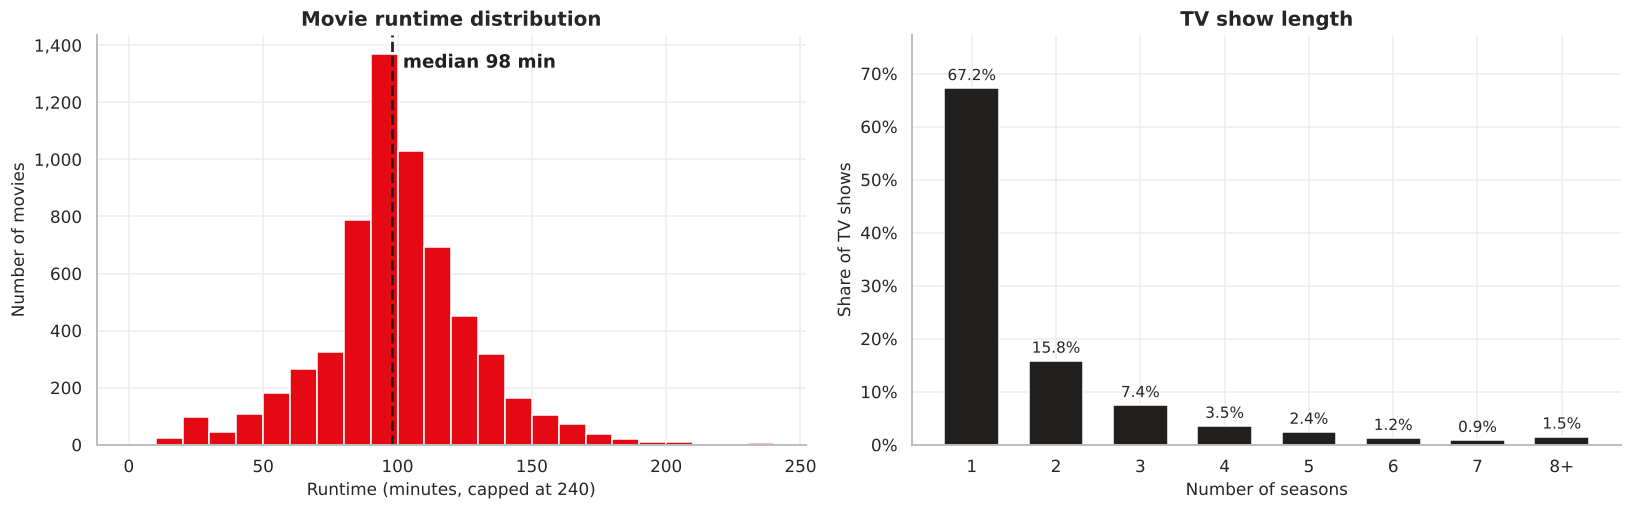

In [26]:
# Supplementary view: what does a typical Movie / TV Show look like? ---------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

movies = df.loc[df["type"] == "Movie", "duration_min"]
ax = axes[0]
ax.hist(movies.clip(upper=240), bins=np.arange(0, 250, 10), color=RED, edgecolor="white")
ax.axvline(movies.median(), color=DARK, ls="--", lw=1.8)
ax.text(movies.median() + 4, ax.get_ylim()[1] * 0.92, f"median {movies.median():.0f} min", color=DARK, fontweight="bold")
ax.set(title="Movie runtime distribution", xlabel="Runtime (minutes, capped at 240)", ylabel="Number of movies")
thousands(ax)

seasons = df.loc[df["type"] == "TV Show", "n_seasons"].astype(int).clip(upper=8)
season_share = seasons.value_counts(normalize=True).sort_index()
ax = axes[1]
bars = ax.bar([str(i) if i < 8 else "8+" for i in season_share.index], season_share.values, color=DARK, width=0.65)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in season_share.values], padding=3, fontsize=10)
ax.set(title="TV show length", xlabel="Number of seasons", ylabel="Share of TV shows", ylim=(0, season_share.max() * 1.15))
percent_axis(ax)

fig.tight_layout()
save_fig(fig, "task2_runtime_and_seasons")
plt.show()

## Step 4 · Compare content proportions

In [27]:
def type_profile(frame: pd.DataFrame) -> pd.DataFrame:
    """Side-by-side profile of Movies vs TV Shows."""
    g = frame.groupby("type")
    rows = {
        "Titles": g.size(),
        "Share of catalog": g.size() / len(frame),
        "Median release year": g["release_year"].median(),
        "Median year added to Netflix": g["year_added"].median(),
        "Median age when added (years)": g["lag_years"].median(),
        "Avg. genre tags per title": g["n_genres"].mean(),
        "Director known": g["director"].apply(lambda s: (s != "Unknown").mean()),
        "Country known (reliable)": g["country_reliable"].apply(lambda s: (~s.isin(["Unknown", "Unverified"])).mean()),
        "Adult-rated (TV-MA / R / NC-17)": g["audience_group"].apply(lambda s: (s == "Adults").mean()),
        "Kids / All-ages rated": g["audience_group"].apply(lambda s: (s == "Kids / All Ages").mean()),
    }
    return pd.DataFrame(rows).T[TYPE_ORDER]


profile_tbl = type_profile(df)
fmt = {
    "Titles": "{:,.0f}", "Share of catalog": "{:.1%}", "Median release year": "{:.0f}",
    "Median year added to Netflix": "{:.0f}", "Median age when added (years)": "{:.0f}",
    "Avg. genre tags per title": "{:.2f}", "Director known": "{:.1%}", "Country known (reliable)": "{:.1%}",
    "Adult-rated (TV-MA / R / NC-17)": "{:.1%}", "Kids / All-ages rated": "{:.1%}",
}
display(HTML(
    pd.DataFrame({t: [fmt[i].format(profile_tbl.loc[i, t]) for i in profile_tbl.index] for t in TYPE_ORDER}, index=profile_tbl.index)
    .style.set_caption("Movies vs TV Shows: side-by-side profile").to_html()
))

,Movie,TV Show
Titles,"6,123","2,663"
Share of catalog,69.7%,30.3%
Median release year,2016,2018
Median year added to Netflix,2019,2019
Median age when added (years),2,0
Avg. genre tags per title,2.15,2.29
Director known,97.2%,9.4%
Country known (reliable),94.9%,85.8%
Adult-rated (TV-MA / R / NC-17),46.7%,43.0%
Kids / All-ages rated,7.2%,17.4%


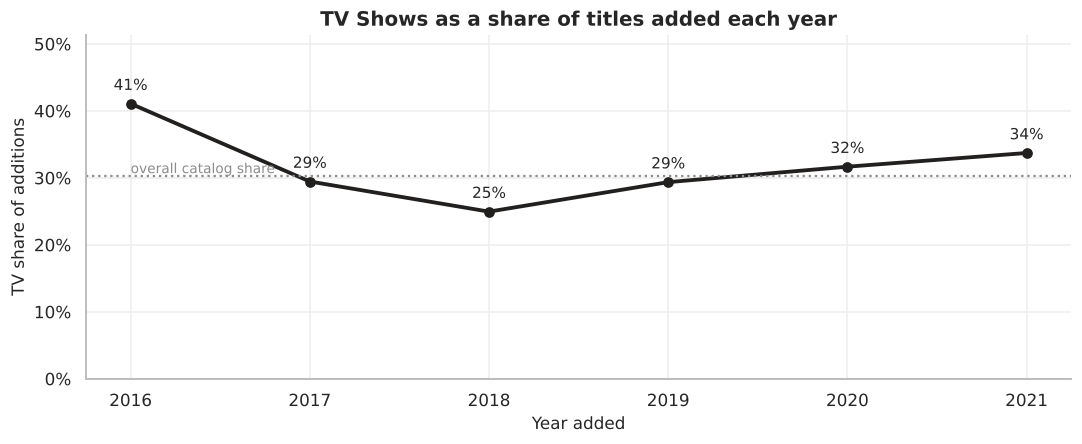

TV share of additions: 28.7% (2016–18) → 31.4% (2019–21); two-proportion z-test p = 0.0088


In [28]:
# Has the balance between Movies and TV shifted? Compare the TV share of additions over time.
tv_share_added = (pd.crosstab(df["year_added"], df["type"], normalize="index")["TV Show"]).loc[2016:]
early = df[df["year_added"].between(2016, 2018)]
late = df[df["year_added"].between(2019, 2021)]
tv_early, tv_late = (early["type"] == "TV Show").mean(), (late["type"] == "TV Show").mean()

# Two-proportion z-test: is the change in TV share between the two periods statistically significant?
n1, n2 = len(early), len(late)
p_pool = ((early["type"] == "TV Show").sum() + (late["type"] == "TV Show").sum()) / (n1 + n2)
z = (tv_late - tv_early) / np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(tv_share_added.index, tv_share_added.values, marker="o", lw=2.5, color=DARK)
for x, y in tv_share_added.items():
    ax.annotate(f"{y:.0%}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=10)
ax.axhline(type_counts["TV Show"] / total_titles, color=GREY, ls=":", lw=1.5)
ax.text(tv_share_added.index[0], type_counts["TV Show"] / total_titles + 0.004, "overall catalog share", color=GREY, fontsize=9)
ax.set(title="TV Shows as a share of titles added each year", xlabel="Year added", ylabel="TV share of additions",
       ylim=(0, tv_share_added.max() * 1.25))
percent_axis(ax)
fig.tight_layout()
save_fig(fig, "task2_tv_share_trend")
plt.show()
print(f"TV share of additions: {tv_early:.1%} (2016–18) → {tv_late:.1%} (2019–21); two-proportion z-test p = {p_value:.4f}")

## Step 5 · Key findings

In [29]:
adult_movie = profile_tbl.loc["Adult-rated (TV-MA / R / NC-17)", "Movie"]
adult_tv = profile_tbl.loc["Adult-rated (TV-MA / R / NC-17)", "TV Show"]
sig = "statistically significant" if p_value < 0.05 else "not statistically significant"
if abs(adult_tv - adult_movie) < 0.03:
    maturity_sentence = "Movies and TV shows have a similar maturity profile."
else:
    maturity_sentence = f"{'TV shows' if adult_tv > adult_movie else 'Movies'} skew more mature."

md(f"""
### Task 2 · Summary report

1. **Movies dominate the catalog.** Netflix lists **{movie_n:,} movies ({movie_n / total_titles:.1%})** and **{tv_n:,} TV shows ({tv_n / total_titles:.1%})** — about **{movies_per_tv:.1f} movies for every TV show**.
2. **The typical movie is a feature-length film.** The median runtime is **{movies.median():.0f} minutes**; {(movies.between(80, 120)).mean():.0%} of movies run between 80 and 120 minutes.
3. **Most TV shows are short-run.** **{season_share.get(1, 0):.0%}** of TV shows have a single season and **{season_share.loc[season_share.index <= 2].sum():.0%}** have two or fewer, which points to many limited series and one-season programmes.
4. **TV's share of new additions {trend_word(tv_early, tv_late)}.** The TV share of titles added went from **{tv_early:.1%}** (2016–18) to **{tv_late:.1%}** (2019–21); the change is **{sig}** (p = {p_value:.3g}), although the year-by-year path is uneven (see Task 6).
5. **TV's weight grows with newer content.** TV shows are only **{era_share.iloc[0]['TV Show']:.0%}** of titles released up to 1999 but **{era_share.iloc[-1]['TV Show']:.0%}** of titles released from 2020 — the catalog is shifting from a film library towards series.
6. **{maturity_sentence}** Adult-rated content (TV-MA / R / NC-17) is {adult_tv:.0%} of TV shows vs {adult_movie:.0%} of movies *(a full rating analysis follows in Task 5)*.

**Business interpretation:** Movies provide breadth, while TV shows are where the catalog is {('expanding' if tv_late > tv_early else 'not expanding')} relative to movies. Because most series are short-run, the catalog depends on constantly commissioning new series rather than on long-running franchises.
""")


### Task 2 · Summary report

1. **Movies dominate the catalog.** Netflix lists **6,123 movies (69.7%)** and **2,663 TV shows (30.3%)** — about **2.3 movies for every TV show**.
2. **The typical movie is a feature-length film.** The median runtime is **98 minutes**; 64% of movies run between 80 and 120 minutes.
3. **Most TV shows are short-run.** **67%** of TV shows have a single season and **83%** have two or fewer, which points to many limited series and one-season programmes.
4. **TV's share of new additions rose.** The TV share of titles added went from **28.7%** (2016–18) to **31.4%** (2019–21); the change is **statistically significant** (p = 0.00877), although the year-by-year path is uneven (see Task 6).
5. **TV's weight grows with newer content.** TV shows are only **9%** of titles released up to 1999 but **49%** of titles released from 2020 — the catalog is shifting from a film library towards series.
6. **Movies skew more mature.** Adult-rated content (TV-MA / R / NC-17) is 43% of TV shows vs 47% of movies *(a full rating analysis follows in Task 5)*.

**Business interpretation:** Movies provide breadth, while TV shows are where the catalog is expanding relative to movies. Because most series are short-run, the catalog depends on constantly commissioning new series rather than on long-running franchises.


<a id="task3"></a>

---

# Task 3 · Country-Wise Netflix Content Analysis  `Medium`

**Goal:** analyse content availability across countries.

| Step | Activity |
|------|----------|
| 1 | Extract and clean country information |
| 2 | Calculate content count by country |
| 3 | Identify the top content-producing countries |
| 4 | Create charts and rankings |
| 5 | Generate business insights |

## Step 1 · Extract and clean country information

Country data is taken from `country_reliable` (see Task 1, §4.2). Records are **exploded** so that a title listing several countries would count once for each — the routine is correct even though this file contains one country per title. `Unknown` and `Unverified` are excluded from every ranking.

In [30]:
NON_COUNTRY = {"Unknown", "Unverified"}

# ISO-3 codes (for the map) and continents (for regional analysis).
COUNTRY_META = {
    "Argentina": ("ARG", "South America"), "Australia": ("AUS", "Oceania"), "Austria": ("AUT", "Europe"),
    "Bangladesh": ("BGD", "Asia"), "Belarus": ("BLR", "Europe"), "Belgium": ("BEL", "Europe"),
    "Brazil": ("BRA", "South America"), "Bulgaria": ("BGR", "Europe"), "Cambodia": ("KHM", "Asia"),
    "Cameroon": ("CMR", "Africa"), "Canada": ("CAN", "North America"), "Chile": ("CHL", "South America"),
    "China": ("CHN", "Asia"), "Colombia": ("COL", "South America"), "Croatia": ("HRV", "Europe"),
    "Cyprus": ("CYP", "Europe"), "Czech Republic": ("CZE", "Europe"), "Denmark": ("DNK", "Europe"),
    "Egypt": ("EGY", "Africa"), "Finland": ("FIN", "Europe"), "France": ("FRA", "Europe"),
    "Georgia": ("GEO", "Asia"), "Germany": ("DEU", "Europe"), "Ghana": ("GHA", "Africa"),
    "Greece": ("GRC", "Europe"), "Guatemala": ("GTM", "North America"), "Hong Kong": ("HKG", "Asia"),
    "Hungary": ("HUN", "Europe"), "Iceland": ("ISL", "Europe"), "India": ("IND", "Asia"),
    "Indonesia": ("IDN", "Asia"), "Iran": ("IRN", "Asia"), "Ireland": ("IRL", "Europe"),
    "Israel": ("ISR", "Asia"), "Italy": ("ITA", "Europe"), "Jamaica": ("JAM", "North America"),
    "Japan": ("JPN", "Asia"), "Jordan": ("JOR", "Asia"), "Kenya": ("KEN", "Africa"),
    "Kuwait": ("KWT", "Asia"), "Lebanon": ("LBN", "Asia"), "Luxembourg": ("LUX", "Europe"),
    "Malaysia": ("MYS", "Asia"), "Mauritius": ("MUS", "Africa"), "Mexico": ("MEX", "North America"),
    "Mozambique": ("MOZ", "Africa"), "Namibia": ("NAM", "Africa"), "Netherlands": ("NLD", "Europe"),
    "New Zealand": ("NZL", "Oceania"), "Nigeria": ("NGA", "Africa"), "Norway": ("NOR", "Europe"),
    "Pakistan": ("PAK", "Asia"), "Paraguay": ("PRY", "South America"), "Peru": ("PER", "South America"),
    "Philippines": ("PHL", "Asia"), "Poland": ("POL", "Europe"), "Portugal": ("PRT", "Europe"),
    "Puerto Rico": ("PRI", "North America"), "Romania": ("ROU", "Europe"), "Russia": ("RUS", "Europe"),
    "Saudi Arabia": ("SAU", "Asia"), "Senegal": ("SEN", "Africa"), "Serbia": ("SRB", "Europe"),
    "Singapore": ("SGP", "Asia"), "Slovenia": ("SVN", "Europe"), "Somalia": ("SOM", "Africa"),
    "South Africa": ("ZAF", "Africa"), "South Korea": ("KOR", "Asia"), "Spain": ("ESP", "Europe"),
    "Sweden": ("SWE", "Europe"), "Switzerland": ("CHE", "Europe"), "Syria": ("SYR", "Asia"),
    "Taiwan": ("TWN", "Asia"), "Thailand": ("THA", "Asia"), "Turkey": ("TUR", "Asia"),
    "Ukraine": ("UKR", "Europe"), "United Arab Emirates": ("ARE", "Asia"), "United Kingdom": ("GBR", "Europe"),
    "United States": ("USA", "North America"), "Uruguay": ("URY", "South America"),
    "Venezuela": ("VEN", "South America"), "Vietnam": ("VNM", "Asia"), "Zimbabwe": ("ZWE", "Africa"),
    # Historical states: mapped to a continent but not drawn on the modern map.
    "Soviet Union": (None, "Europe"), "West Germany": (None, "Europe"),
}


def explode_countries(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    """One row per (title, country) pair; Unknown / Unverified removed."""
    out = frame.assign(country_item=frame[column].str.split(",")).explode("country_item")
    out["country_item"] = out["country_item"].str.strip()
    return out[~out["country_item"].isin(NON_COUNTRY)].reset_index(drop=True)


country_df = explode_countries(df, "country_reliable")
missing_meta = sorted(set(country_df["country_item"]) - set(COUNTRY_META))
assert not missing_meta, f"Add these countries to COUNTRY_META: {missing_meta}"

n_known = df.loc[~df["country_reliable"].isin(NON_COUNTRY), "show_id"].nunique()
n_unknown = int((df["country_reliable"] == "Unknown").sum())
n_unverified = int((df["country_reliable"] == "Unverified").sum())
print(f"Titles with a reliable country : {n_known:,} ({n_known / len(df):.1%})")
print(f"Titles with no country         : {n_unknown:,} ({n_unknown / len(df):.1%})  -> excluded")
print(f"Titles with unverified country : {n_unverified:,} ({n_unverified / len(df):.1%})  -> excluded")
print(f"Countries represented          : {country_df['country_item'].nunique()}")

Titles with a reliable country : 8,098 (92.2%)
Titles with no country         : 287 (3.3%)  -> excluded
Titles with unverified country : 401 (4.6%)  -> excluded
Countries represented          : 85


## Step 2 · Content count by country

In [31]:
def country_table(cdf: pd.DataFrame, denominator: int) -> pd.DataFrame:
    """Ranking table: titles, share, cumulative share, Movie/TV split."""
    t = pd.crosstab(cdf["country_item"], cdf["type"]).reindex(columns=TYPE_ORDER, fill_value=0)
    t["Titles"] = t.sum(axis=1)
    t = t.sort_values("Titles", ascending=False)
    t["Share"] = t["Titles"] / denominator
    t["Cumulative share"] = t["Share"].cumsum()
    t["TV share"] = t["TV Show"] / t["Titles"]
    t.insert(0, "Rank", range(1, len(t) + 1))
    t["Continent"] = [COUNTRY_META[c][1] for c in t.index]
    return t.rename_axis("Country")


rank = country_table(country_df, n_known)
display(
    rank.head(15)
    .style.format({"Movie": "{:,.0f}", "TV Show": "{:,.0f}", "Titles": "{:,.0f}", "Share": "{:.1%}",
                   "Cumulative share": "{:.1%}", "TV share": "{:.0%}"})
    .background_gradient(subset=["Titles"], cmap="Reds")
    .set_caption(f"Top 15 countries by number of titles (share = % of the {n_known:,} titles with a reliable country)")
)

type,Rank,Movie,TV Show,Titles,Share,Cumulative share,TV share,Continent
Country,,,,,,,,
United States,1,"2,395",845,"3,240",40.0%,40.0%,26%,North America
India,2,975,81,"1,056",13.0%,53.1%,8%,Asia
United Kingdom,3,387,251,638,7.9%,60.9%,39%,Europe
Canada,4,187,84,271,3.3%,64.3%,31%,North America
Japan,5,87,172,259,3.2%,67.5%,66%,Asia
South Korea,6,49,165,214,2.6%,70.1%,77%,Asia
France,7,148,65,213,2.6%,72.7%,31%,Europe
Spain,8,129,53,182,2.2%,75.0%,29%,Europe
Mexico,9,90,48,138,1.7%,76.7%,35%,North America


## Step 3 · Top content-producing countries

In [32]:
top10 = rank.head(10)
us_share = rank.loc["United States", "Share"]
top3_share, top5_share, top10_share = rank["Share"].head(3).sum(), rank["Share"].head(5).sum(), rank["Share"].head(10).sum()
hhi = float((rank["Share"] ** 2).sum() * 10_000)           # Herfindahl-Hirschman index (0-10,000)
tail = int((rank["Titles"] < 10).sum())

concentration = pd.DataFrame({
    "Metric": ["Countries represented", "#1 country", "Top 3 countries", "Top 5 countries", "Top 10 countries",
               "Countries with fewer than 10 titles", "Herfindahl–Hirschman Index (0–10,000)"],
    "Value": [f"{len(rank)}", f"{rank.index[0]} — {rank['Share'].iloc[0]:.1%}", f"{top3_share:.1%}", f"{top5_share:.1%}",
              f"{top10_share:.1%}", f"{tail} ({tail / len(rank):.0%} of countries)", f"{hhi:,.0f}"],
})
display(concentration.style.hide(axis="index").set_caption("Market concentration of the catalog"))

Metric,Value
Countries represented,85
#1 country,United States — 40.0%
Top 3 countries,60.9%
Top 5 countries,67.5%
Top 10 countries,78.2%
Countries with fewer than 10 titles,42 (49% of countries)
"Herfindahl–Hirschman Index (0–10,000)","1,897"


### Sensitivity check: does the Task 1 country decision matter?

The table below compares the ranking built from the **original** `country` column with the one built from `country_reliable`.

In [33]:
raw_df = explode_countries(df, "country")
raw_rank = country_table(raw_df, int((df["country"] != "Unknown").sum()))

compare = (raw_rank[["Rank", "Titles"]].rename(columns={"Rank": "Rank (original)", "Titles": "Titles (original)"})
           .join(rank[["Rank", "Titles"]].rename(columns={"Rank": "Rank (reliable)", "Titles": "Titles (reliable)"}), how="outer")
           .sort_values("Rank (original)").head(10))
compare["Rank change"] = (compare["Rank (original)"] - compare["Rank (reliable)"]).fillna(0).astype(int)
display(compare.style.format("{:,.0f}", na_rep="–").set_caption("Top 10 by original label vs reliable label"))

type,Rank (original),Titles (original),Rank (reliable),Titles (reliable),Rank change
Country,,,,,
United States,1,"3,240",1,"3,240",0
India,2,"1,056",2,"1,056",0
United Kingdom,3,638,3,638,0
Pakistan,4,420,38,19,-34
Canada,5,271,4,271,1
Japan,6,259,5,259,1
South Korea,7,214,6,214,1
France,8,213,7,213,1
Spain,9,182,8,182,1


## Step 4 · Charts and rankings

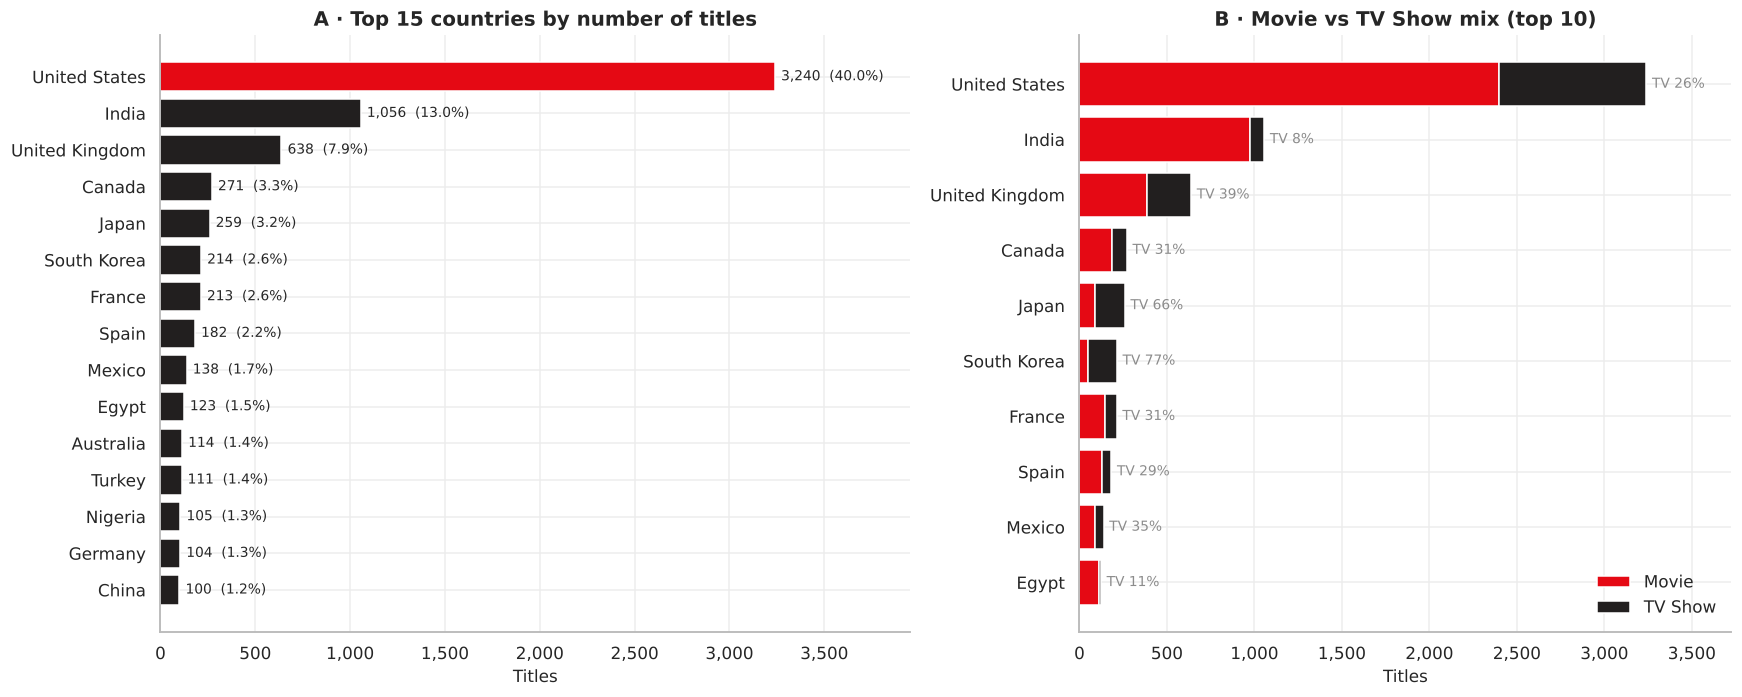

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})

# (A) Top 15 horizontal bars
top15 = rank.head(15).iloc[::-1]
ax = axes[0]
colors = [RED if c == rank.index[0] else DARK for c in top15.index]
bars = ax.barh(top15.index, top15["Titles"], color=colors)
ax.bar_label(bars, labels=[f"{v:,}  ({s:.1%})" for v, s in zip(top15["Titles"], top15["Share"])], padding=4, fontsize=9)
ax.set(title="A · Top 15 countries by number of titles", xlabel="Titles", xlim=(0, top15["Titles"].max() * 1.22))
thousands(ax, "x")

# (B) Movie vs TV composition, top 10
ax = axes[1]
t10 = rank.head(10).iloc[::-1]
ax.barh(t10.index, t10["Movie"], color=RED, label="Movie")
ax.barh(t10.index, t10["TV Show"], left=t10["Movie"], color=DARK, label="TV Show")
for i, (c, row) in enumerate(t10.iterrows()):
    ax.text(row["Titles"] + t10["Titles"].max() * 0.01, i, f"TV {row['TV share']:.0%}", va="center", fontsize=9, color=GREY)
ax.set(title="B · Movie vs TV Show mix (top 10)", xlabel="Titles", xlim=(0, t10["Titles"].max() * 1.15))
thousands(ax, "x")
ax.legend(loc="lower right")

fig.tight_layout()
save_fig(fig, "task3_country_rankings")
plt.show()

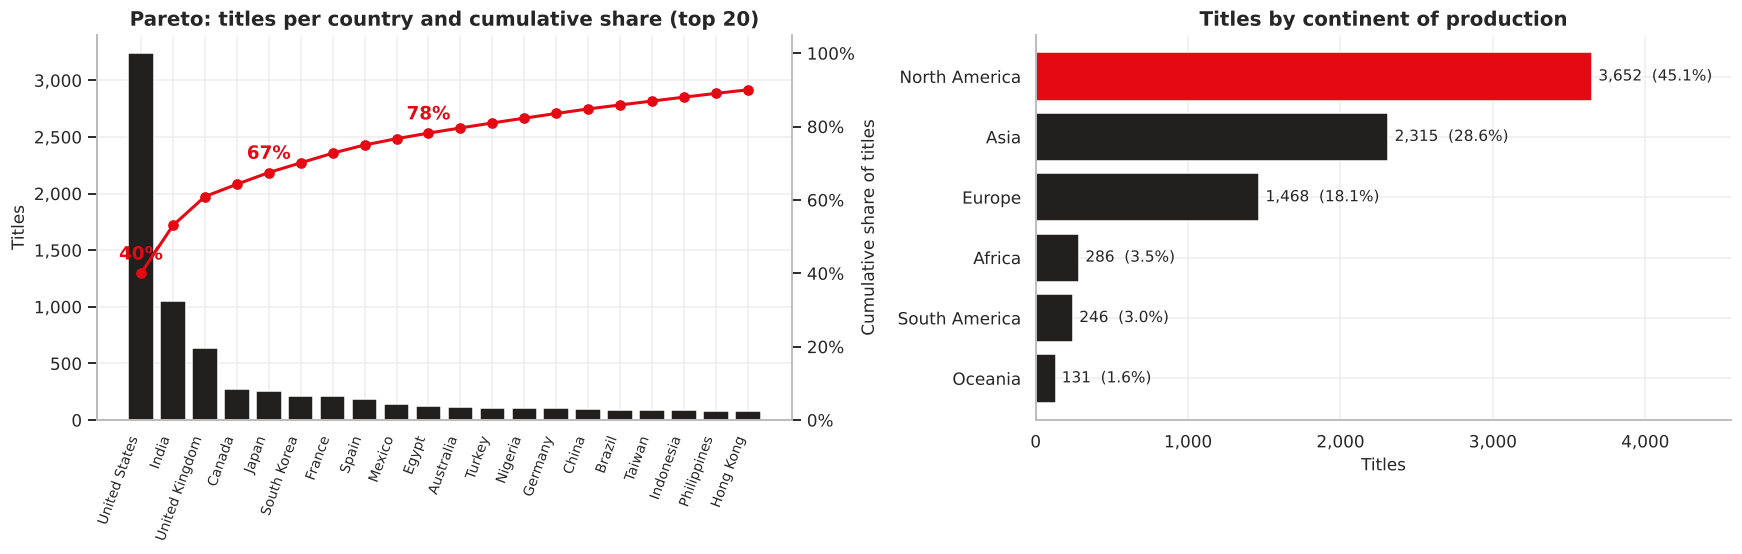

In [35]:
# Pareto chart: how concentrated is the catalog?  +  continent view -----------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))

top20 = rank.head(20)
ax = axes[0]
ax.bar(range(len(top20)), top20["Titles"], color=DARK)
ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20.index, rotation=70, ha="right", fontsize=9)
ax.set(title="Pareto: titles per country and cumulative share (top 20)", ylabel="Titles")
thousands(ax)
ax2 = ax.twinx()
ax2.plot(range(len(top20)), top20["Cumulative share"], color=RED, marker="o", lw=2)
ax2.set(ylim=(0, 1.05), ylabel="Cumulative share of titles")
ax2.spines["right"].set_visible(True)
percent_axis(ax2)
for k in (0, 4, 9):
    ax2.annotate(f"{top20['Cumulative share'].iloc[k]:.0%}", (k, top20["Cumulative share"].iloc[k]), textcoords="offset points",
                 xytext=(0, 9), ha="center", color=RED, fontweight="bold")
ax2.grid(False)

country_df["Continent"] = country_df["country_item"].map(lambda c: COUNTRY_META[c][1])
continent = country_df.groupby("Continent").size().sort_values()
ax = axes[1]
bars = ax.barh(continent.index, continent.values, color=[RED if c == continent.idxmax() else DARK for c in continent.index])
ax.bar_label(bars, labels=[f"{v:,}  ({v / continent.sum():.1%})" for v in continent.values], padding=4, fontsize=10)
ax.set(title="Titles by continent of production", xlabel="Titles", xlim=(0, continent.max() * 1.25))
thousands(ax, "x")

fig.tight_layout()
save_fig(fig, "task3_pareto_and_continents")
plt.show()

In [36]:
# Geographic view (interactive) -----------------------------------------------------------
geo = rank.reset_index()
geo["iso3"] = geo["Country"].map(lambda c: COUNTRY_META[c][0])
geo = geo.dropna(subset=["iso3"])
geo["log10_titles"] = np.log10(geo["Titles"])

fig = px.choropleth(
    geo, locations="iso3", color="log10_titles", hover_name="Country",
    hover_data={"iso3": False, "log10_titles": False, "Titles": ":,", "Share": ":.1%", "TV share": ":.0%"},
    color_continuous_scale=["#F5F5F5", "#F6B3B6", RED, "#5C0A0E"],
    title="Netflix titles by production country (log colour scale; hover for details)",
)
ticks = [1, 10, 100, 1000]
fig.update_layout(
    coloraxis_colorbar=dict(title="Titles", tickvals=np.log10(ticks), ticktext=[f"{t:,}" for t in ticks]),
    geo=dict(showframe=False, showcoastlines=False, projection_type="natural earth", bgcolor="white"),
    margin=dict(l=0, r=0, t=60, b=0), height=520,
)
fig.show()

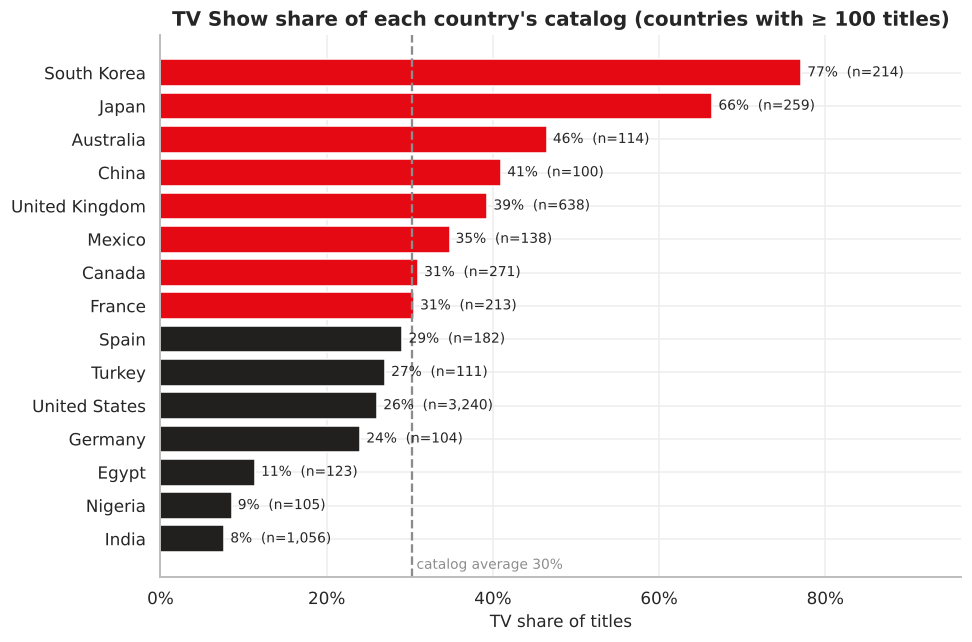

In [37]:
# Which countries lean towards TV? (countries with >= 100 titles) --------------------------
big = rank[rank["Titles"] >= 100].sort_values("TV share")
fig, ax = plt.subplots(figsize=(9, 6))
overall_tv = (df["type"] == "TV Show").mean()
bars = ax.barh(big.index, big["TV share"], color=[RED if v > overall_tv else DARK for v in big["TV share"]])
ax.bar_label(bars, labels=[f"{v:.0%}  (n={n:,})" for v, n in zip(big["TV share"], big["Titles"])], padding=4, fontsize=9)
ax.axvline(overall_tv, color=GREY, ls="--")
ax.text(overall_tv + 0.005, -0.9, f"catalog average {overall_tv:.0%}", color=GREY, fontsize=9)
ax.set(title="TV Show share of each country's catalog (countries with ≥ 100 titles)", xlabel="TV share of titles",
       xlim=(0, big["TV share"].max() * 1.25))
percent_axis(ax, "x")
fig.tight_layout()
save_fig(fig, "task3_tv_share_by_country")
plt.show()

## Step 5 · Business insights

In [38]:
top2, top3 = rank.index[1], rank.index[2]
non_us = 1 - us_share
cont_share = (continent / continent.sum()).sort_values(ascending=False)
lead_other = cont_share.index[1]
tv_lean = big.sort_values("TV share", ascending=False)
mov_lean = big.sort_values("TV share")
orig_top = raw_rank.index[0:5].tolist()
moved = compare[compare["Rank change"] != 0].index.tolist()

md(f"""
### Task 3 · Business insights

1. **The United States is the anchor market but not the whole story.** It supplies **{us_share:.1%}** of titles with a known country; the remaining **{non_us:.1%}** come from **{len(rank) - 1} other countries**.
2. **The catalog is concentrated at the top.** The top 5 countries account for **{top5_share:.1%}** of titles and the top 10 for **{top10_share:.1%}**, while **{tail} of {len(rank)} countries** ({tail / len(rank):.0%}) have fewer than 10 titles. The HHI of **{hhi:,.0f}** is {'highly concentrated' if hhi > 2500 else ('moderately concentrated' if hhi > 1500 else 'diversified')} on the conventional scale — driven mostly by the US.
3. **{top2} and {top3} are the next two pillars** — #2 **{top2}** ({rank.loc[top2, 'Share']:.1%}) and #3 **{top3}** ({rank.loc[top3, 'Share']:.1%}). Together with the US they provide **{top3_share:.1%}** of titles.
4. **{lead_other} is the leading region outside {cont_share.index[0]}.** Continents by share of titles: {', '.join(f'{c} {v:.1%}' for c, v in cont_share.items())}.
5. **Format mix differs sharply by country.** The most TV-oriented large markets are **{', '.join(tv_lean.index[:3])}** ({', '.join(f'{v:.0%}' for v in tv_lean['TV share'].iloc[:3])} TV), whereas **{', '.join(mov_lean.index[:3])}** are overwhelmingly movie-driven ({', '.join(f'{v:.0%}' for v in mov_lean['TV share'].iloc[:3])} TV) — different local content strategies for different markets.
6. **Data-quality caution.** Using the original `country` column would have made **Pakistan** the {raw_rank.index.get_loc('Pakistan') + 1 if 'Pakistan' in raw_rank.index else 'n/a'}th largest producer with {int(raw_rank.loc['Pakistan', 'Titles']) if 'Pakistan' in raw_rank.index else 0} titles. After isolating the {n_unverified} records with an unreliable label, the country ranks #{rank.index.get_loc('Pakistan') + 1 if 'Pakistan' in rank.index else 'n/a'} with {int(rank.loc['Pakistan', 'Titles']) if 'Pakistan' in rank.index else 0} titles. Source-system country tagging should be corrected before country-level decisions are made.

**Recommendation:** treat {rank.index[0]}, {top2} and {top3} as the core supply markets; evaluate TV-heavy markets as sources of series that can be exported globally; and invest in metadata quality so that {(n_unknown + n_unverified) / len(df):.1%} of titles are no longer "country-less" in geographic analytics.
""")


### Task 3 · Business insights

1. **The United States is the anchor market but not the whole story.** It supplies **40.0%** of titles with a known country; the remaining **60.0%** come from **84 other countries**.
2. **The catalog is concentrated at the top.** The top 5 countries account for **67.5%** of titles and the top 10 for **78.2%**, while **42 of 85 countries** (49%) have fewer than 10 titles. The HHI of **1,897** is moderately concentrated on the conventional scale — driven mostly by the US.
3. **India and United Kingdom are the next two pillars** — #2 **India** (13.0%) and #3 **United Kingdom** (7.9%). Together with the US they provide **60.9%** of titles.
4. **Asia is the leading region outside North America.** Continents by share of titles: North America 45.1%, Asia 28.6%, Europe 18.1%, Africa 3.5%, South America 3.0%, Oceania 1.6%.
5. **Format mix differs sharply by country.** The most TV-oriented large markets are **South Korea, Japan, Australia** (77%, 66%, 46% TV), whereas **India, Nigeria, Egypt** are overwhelmingly movie-driven (8%, 9%, 11% TV) — different local content strategies for different markets.
6. **Data-quality caution.** Using the original `country` column would have made **Pakistan** the 4th largest producer with 420 titles. After isolating the 401 records with an unreliable label, the country ranks #38 with 19 titles. Source-system country tagging should be corrected before country-level decisions are made.

**Recommendation:** treat United States, India and United Kingdom as the core supply markets; evaluate TV-heavy markets as sources of series that can be exported globally; and invest in metadata quality so that 7.8% of titles are no longer "country-less" in geographic analytics.


<a id="task4"></a>

---

# Task 4 · Trend Analysis by Release Year  `Medium`

**Goal:** analyse how Netflix content production has changed over time.

| Step | Activity |
|------|----------|
| 1 | Organise content by release year |
| 2 | Calculate yearly content releases |
| 3 | Identify growth and decline trends |
| 4 | Create trend visualisations |
| 5 | Interpret business patterns |

Two different clocks exist in this dataset and both are analysed:
* **`release_year`** — when the title was *produced / released* (content production trend).
* **`year_added`** — when Netflix *added it to the platform* (acquisition / catalog-building trend).

## Step 1 · Organise content by release year

In [39]:
LAST_FULL_YEAR = (PARTIAL_YEAR - 1) if PARTIAL_YEAR else int(df["release_year"].max())
years = range(int(df["release_year"].min()), int(df["release_year"].max()) + 1)

yearly = df.groupby("release_year").size().reindex(years, fill_value=0).rename("titles")
yearly_type = pd.crosstab(df["release_year"], df["type"]).reindex(years, fill_value=0)[TYPE_ORDER]

pre_1990 = yearly.loc[:1989].sum()
print(f"Release years span {years[0]}–{years[-1]}, but only {pre_1990:,} titles ({pre_1990 / len(df):.1%}) were released before 1990,")
print("so the analysis concentrates on 2000 onwards where the data is dense.")

# Decade view
decade = (df["release_year"] // 10 * 10).rename("Decade")
decade_tbl = pd.crosstab(decade, df["type"]).reindex(columns=TYPE_ORDER)
decade_tbl["Titles"] = decade_tbl.sum(axis=1)
decade_tbl["Share of catalog"] = decade_tbl["Titles"] / len(df)
decade_tbl["TV share"] = decade_tbl["TV Show"] / decade_tbl["Titles"]
decade_tbl.index = [f"{d}s" for d in decade_tbl.index]
display(decade_tbl.tail(8).style.format({"Movie": "{:,.0f}", "TV Show": "{:,.0f}", "Titles": "{:,.0f}",
                                         "Share of catalog": "{:.1%}", "TV share": "{:.0%}"})
        .set_caption("Titles by release decade"))

Release years span 1925–2021, but only 251 titles (2.9%) were released before 1990,
so the analysis concentrates on 2000 onwards where the data is dense.


type,Movie,TV Show,Titles,Share of catalog,TV share
1950s,11,0,11,0.1%,0%
1960s,23,2,25,0.3%,8%
1970s,66,4,70,0.8%,6%
1980s,122,7,129,1.5%,5%
1990s,241,33,274,3.1%,12%
2000s,677,130,807,9.2%,16%
2010s,"4,176","1,733","5,909",67.3%,29%
2020s,794,751,"1,545",17.6%,49%


## Step 2 · Calculate yearly content releases

In [40]:
trend = pd.DataFrame({"Titles": yearly})
trend["YoY change (%)"] = trend["Titles"].pct_change().replace([np.inf, -np.inf], np.nan) * 100
trend["3-yr rolling avg"] = trend["Titles"].rolling(3, center=True).mean()
trend["Movies"], trend["TV Shows"] = yearly_type["Movie"], yearly_type["TV Show"]
trend["Partial year"] = trend.index == PARTIAL_YEAR

recent = trend.loc[2005:]
display(
    recent.style.format({"Titles": "{:,.0f}", "YoY change (%)": "{:+.1f}%", "3-yr rolling avg": "{:,.0f}",
                         "Movies": "{:,.0f}", "TV Shows": "{:,.0f}"}, na_rep="–")
    .background_gradient(subset=["Titles"], cmap="Reds")
    .map(lambda v: "color:#0a7d33" if isinstance(v, float) and v > 0 else ("color:#c00" if isinstance(v, float) and v < 0 else ""), subset=["YoY change (%)"])
    .set_caption(f"Yearly releases, 2005–{years[-1]}  (partial year: {PARTIAL_YEAR})")
)

,Titles,YoY change (%),3-yr rolling avg,Movies,TV Shows,Partial year
release_year,,,,,,
2005,80,+25.0%,80,67,13,False
2006,96,+20.0%,88,82,14,False
2007,88,-8.3%,106,74,14,False
2008,135,+53.4%,125,113,22,False
2009,152,+12.6%,160,118,34,False
2010,192,+26.3%,176,153,39,False
2011,185,-3.6%,204,145,40,False
2012,236,+27.6%,236,173,63,False
2013,286,+21.2%,291,225,61,False


## Step 3 · Identify growth and decline trends

The statistics below are computed on **complete years only**; the partial final year is excluded so that it is not mistaken for a decline.

In [41]:
complete = yearly.loc[:LAST_FULL_YEAR]
peak_year = int(complete.loc[2000:].idxmax())
peak_n = int(complete.loc[peak_year])

TREND_START = 2010
cagr = (peak_n / complete.loc[TREND_START]) ** (1 / (peak_year - TREND_START)) - 1

# Linear trend over the expansion window
x = np.arange(TREND_START, peak_year + 1)
lr = stats.linregress(x, complete.loc[TREND_START:peak_year].values)

post_peak_last = int(complete.loc[LAST_FULL_YEAR])
post_peak_change = post_peak_last / peak_n - 1
covid_change = complete.loc[2020] / complete.loc[2019] - 1 if 2020 in complete.index and LAST_FULL_YEAR >= 2020 else np.nan

phases = pd.DataFrame([
    {"Phase": f"Early catalog (2000–{TREND_START - 1})", "Years": TREND_START - 2000,
     "Avg titles / year": complete.loc[2000:TREND_START - 1].mean(),
     "Net change": complete.loc[TREND_START - 1] / complete.loc[2000] - 1},
    {"Phase": f"Expansion ({TREND_START}–{peak_year})", "Years": peak_year - TREND_START + 1,
     "Avg titles / year": complete.loc[TREND_START:peak_year].mean(),
     "Net change": complete.loc[peak_year] / complete.loc[TREND_START] - 1},
    {"Phase": f"Post-peak ({peak_year + 1}–{LAST_FULL_YEAR})", "Years": LAST_FULL_YEAR - peak_year,
     "Avg titles / year": complete.loc[peak_year + 1:LAST_FULL_YEAR].mean(),
     "Net change": post_peak_change},
])
display(phases.style.hide(axis="index").format({"Avg titles / year": "{:,.0f}", "Net change": "{:+.0%}"})
        .set_caption("Growth phases (complete years only)"))

print(f"Peak release year               : {peak_year}  ({peak_n:,} titles)")
print(f"Compound annual growth {TREND_START}→{peak_year}: {cagr:+.1%} per year")
print(f"Linear trend {TREND_START}→{peak_year}         : +{lr.slope:,.0f} titles per year (R² = {lr.rvalue ** 2:.2f})")
print(f"{peak_year} → {LAST_FULL_YEAR}                    : {post_peak_change:+.1%}")

Phase,Years,Avg titles / year,Net change
Early catalog (2000–2009),10,81,+311%
Expansion (2010–2018),9,542,+496%
Post-peak (2019–2020),2,991,-17%


Peak release year               : 2018  (1,144 titles)
Compound annual growth 2010→2018: +25.0% per year
Linear trend 2010→2018         : +132 titles per year (R² = 0.89)
2018 → 2020                    : -16.7%


## Step 4 · Trend visualisations

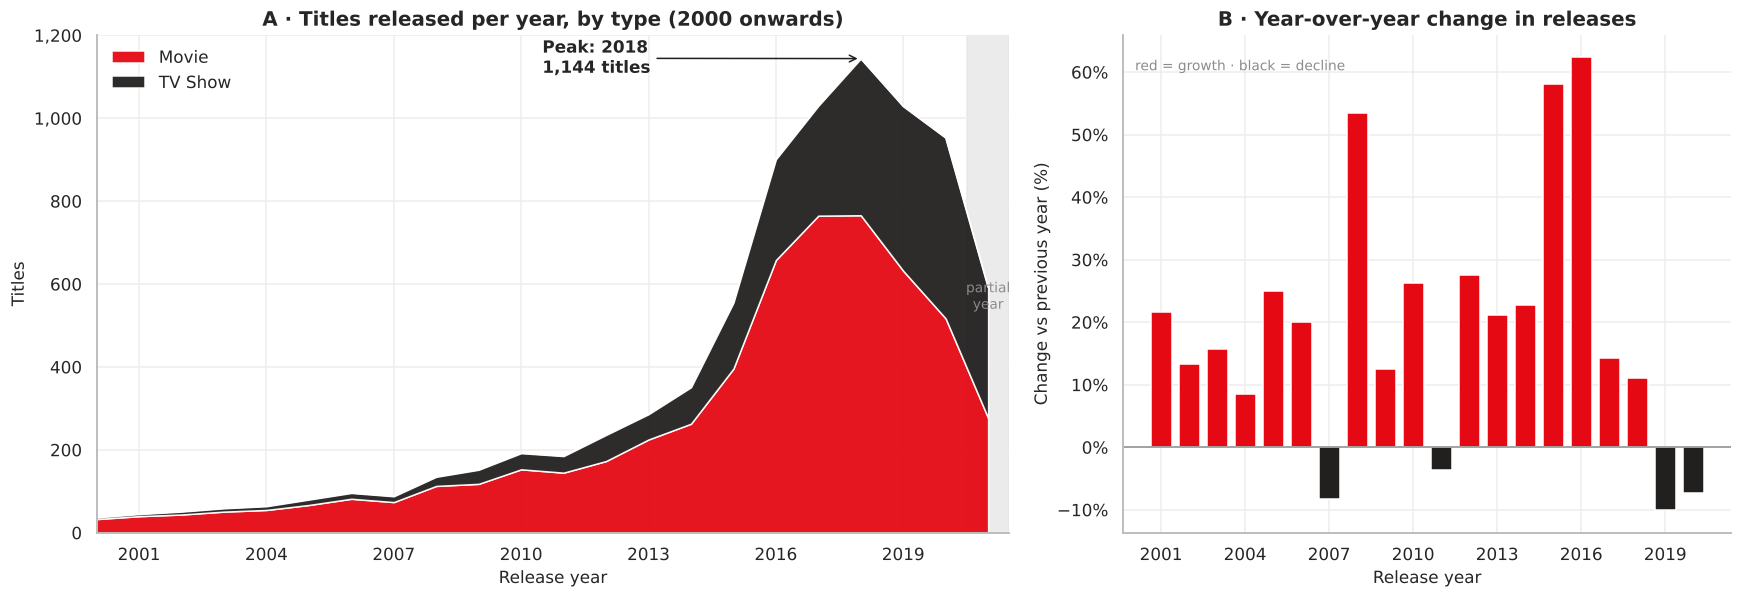

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.5, 1]})

# (A) stacked area by type
ax = axes[0]
span = yearly_type.loc[2000:]
ax.stackplot(span.index, span["Movie"], span["TV Show"], colors=[RED, DARK], labels=TYPE_ORDER, alpha=0.95)
ax.plot(span.index, span.sum(axis=1), color="white", lw=1)
if PARTIAL_YEAR:
    ax.axvspan(PARTIAL_YEAR - 0.5, PARTIAL_YEAR + 0.5, color=LIGHT, alpha=0.8, zorder=0)
    ax.text(PARTIAL_YEAR, ax.get_ylim()[1] * 0.45, "partial\nyear", ha="center", color=GREY, fontsize=9)
ax.annotate(f"Peak: {peak_year}\n{peak_n:,} titles", xy=(peak_year, peak_n), xytext=(peak_year - 7.5, peak_n * 0.97),
            arrowprops=dict(arrowstyle="->", color=DARK), fontsize=11, fontweight="bold")
ax.set(title="A · Titles released per year, by type (2000 onwards)", xlabel="Release year", ylabel="Titles", xlim=(2000, years[-1] + 0.5))
thousands(ax)
ax.legend(loc="upper left")

# (B) YoY growth
ax = axes[1]
yoy = trend.loc[2001:LAST_FULL_YEAR, "YoY change (%)"]
ax.bar(yoy.index, yoy.values, color=[RED if v >= 0 else DARK for v in yoy.values], width=0.75)
ax.axhline(0, color=GREY, lw=1)
ax.set(title="B · Year-over-year change in releases", xlabel="Release year", ylabel="Change vs previous year (%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.text(0.02, 0.95, "red = growth · black = decline", transform=ax.transAxes, fontsize=9, color=GREY, va="top")

fig.tight_layout()
save_fig(fig, "task4_release_trends")
plt.show()

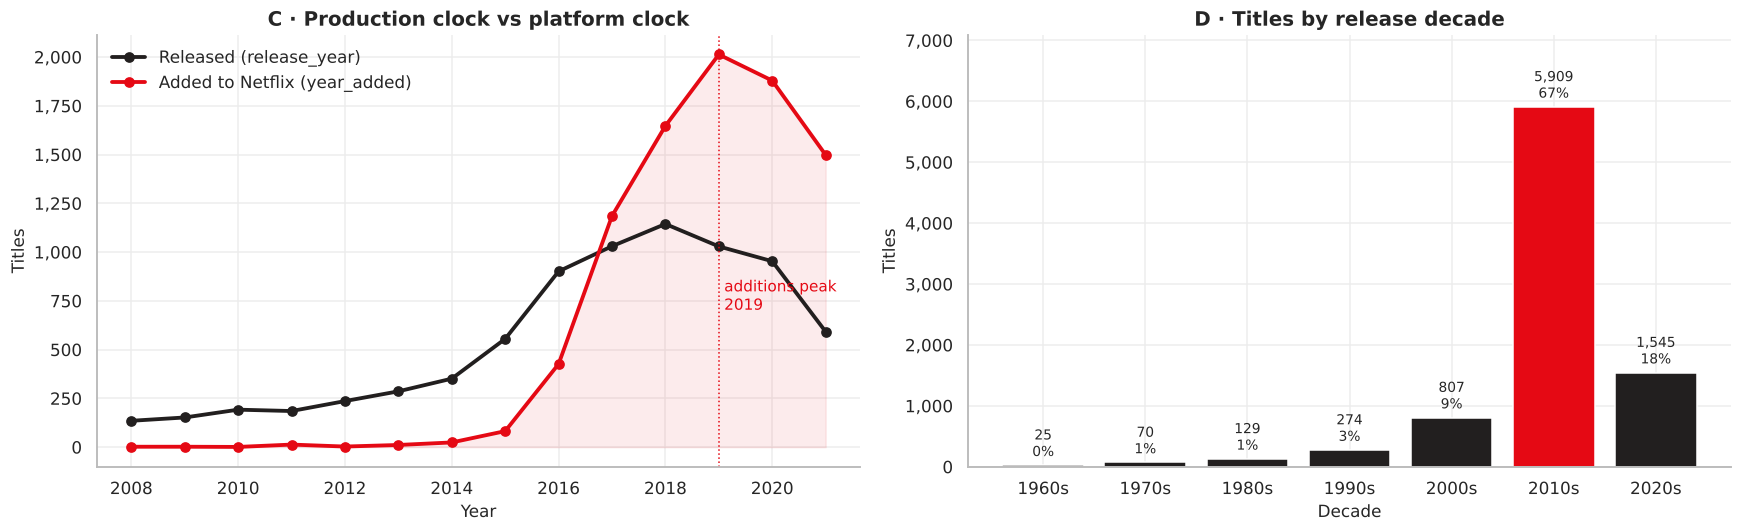

In [43]:
# Two clocks: when titles were RELEASED vs when Netflix ADDED them ------------------------------
added_yearly = df.groupby("year_added").size().reindex(range(2008, int(df["year_added"].max()) + 1), fill_value=0)
rel_aligned = yearly.reindex(added_yearly.index, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
ax.plot(rel_aligned.index, rel_aligned.values, color=DARK, lw=2.5, marker="o", label="Released (release_year)")
ax.plot(added_yearly.index, added_yearly.values, color=RED, lw=2.5, marker="o", label="Added to Netflix (year_added)")
ax.fill_between(added_yearly.index, added_yearly.values, color=RED, alpha=0.08)
ax.axvline(added_yearly.loc[:LAST_FULL_YEAR].idxmax(), color=RED, ls=":", lw=1)
ax.text(added_yearly.loc[:LAST_FULL_YEAR].idxmax() + 0.1, added_yearly.max() * 0.35, f"additions peak\n{added_yearly.loc[:LAST_FULL_YEAR].idxmax()}", color=RED, fontsize=10)
ax.set(title="C · Production clock vs platform clock", xlabel="Year", ylabel="Titles")
thousands(ax)
ax.legend()

ax = axes[1]
t_dec = decade_tbl.tail(7)
bars = ax.bar(t_dec.index, t_dec["Titles"], color=[RED if i == t_dec["Titles"].idxmax() else DARK for i in t_dec.index])
ax.bar_label(bars, labels=[f"{v:,}\n{s:.0%}" for v, s in zip(t_dec["Titles"], t_dec["Share of catalog"])], padding=3, fontsize=9)
ax.set(title="D · Titles by release decade", xlabel="Decade", ylabel="Titles", ylim=(0, t_dec["Titles"].max() * 1.2))
thousands(ax)

fig.tight_layout()
save_fig(fig, "task4_two_clocks_and_decades")
plt.show()

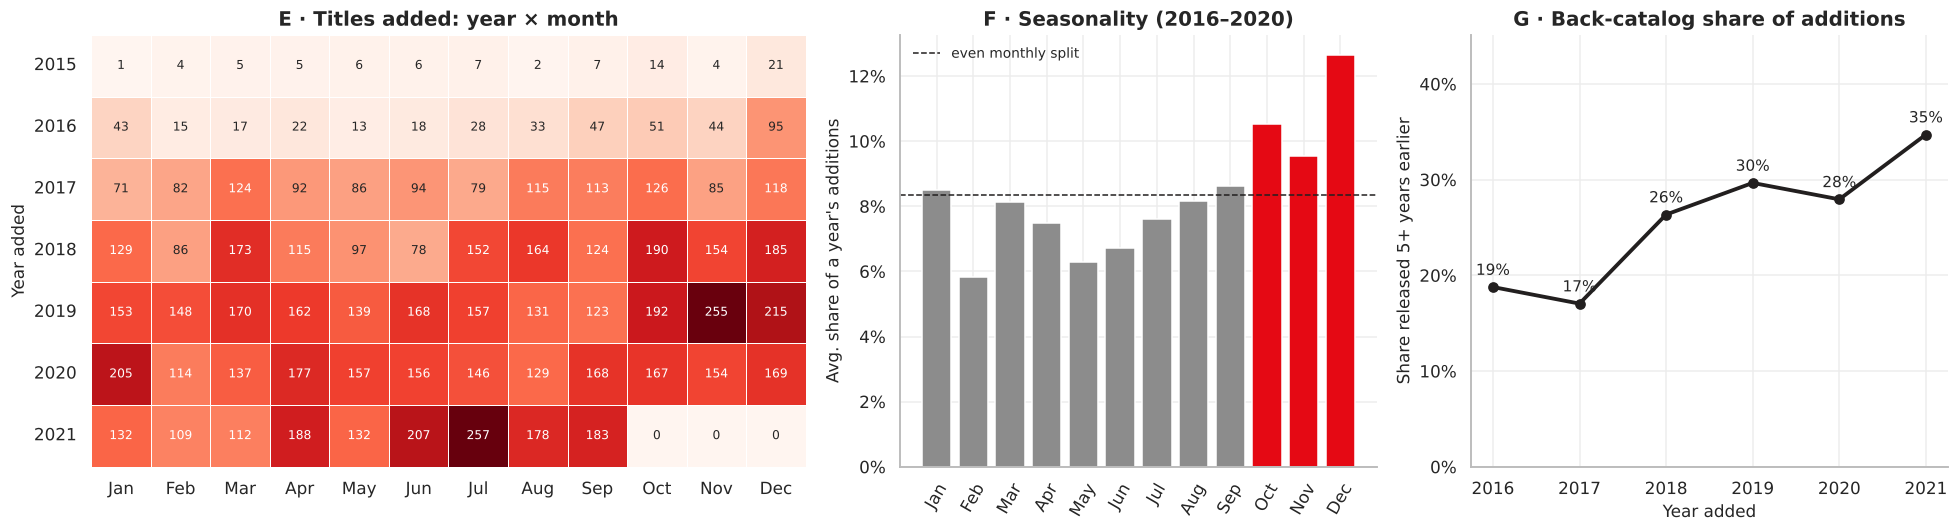

In [44]:
# Seasonality and catalog freshness -------------------------------------------------------------
month_tbl = pd.crosstab(df["year_added"], df["month_added"]).reindex(columns=range(1, 13), fill_value=0)
season_years = [y for y in month_tbl.index if 2016 <= y <= LAST_FULL_YEAR]
month_share = month_tbl.loc[season_years].div(month_tbl.loc[season_years].sum(axis=1), axis=0)
avg_month_share = month_share.mean()
top_months = avg_month_share.sort_values(ascending=False).index[:3]

BACKCATALOG_YEARS = 5      # a title is "back-catalog" if it was released 5+ years before being added
fresh = (df.assign(lag_pos=df["lag_years"].clip(lower=0)).groupby("year_added")
         .agg(backcatalog_share=("lag_pos", lambda s: (s >= BACKCATALOG_YEARS).mean()), n=("show_id", "size")))
fresh = fresh[fresh["n"] >= 50].loc[2016:]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1.5, 1, 1]})

ax = axes[0]
hm = month_tbl.loc[2015:].copy()
hm.columns = list(calendar.month_abbr)[1:]
sns.heatmap(hm, cmap="Reds", annot=True, fmt="d", linewidths=0.5, linecolor="white", cbar=False, ax=ax, annot_kws={"fontsize": 8})
ax.set(title="E · Titles added: year × month", xlabel="", ylabel="Year added")
ax.tick_params(axis="y", rotation=0)

ax = axes[1]
bars = ax.bar(list(calendar.month_abbr)[1:], avg_month_share.values, color=[RED if m in top_months else GREY for m in avg_month_share.index])
ax.axhline(1 / 12, color=DARK, ls="--", lw=1, label="even monthly split")
ax.legend(loc="upper left", fontsize=9)
ax.set(title=f"F · Seasonality ({season_years[0]}–{season_years[-1]})", ylabel="Avg. share of a year's additions")
ax.tick_params(axis="x", rotation=60)
percent_axis(ax)

ax = axes[2]
ax.plot(fresh.index, fresh["backcatalog_share"], marker="o", lw=2.5, color=DARK)
for xv, yv in fresh["backcatalog_share"].items():
    ax.annotate(f"{yv:.0%}", (xv, yv), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=10)
ax.set(title=f"G · Back-catalog share of additions", xlabel="Year added", ylabel=f"Share released {BACKCATALOG_YEARS}+ years earlier",
       ylim=(0, fresh["backcatalog_share"].max() * 1.3))
percent_axis(ax)

fig.tight_layout()
save_fig(fig, "task4_seasonality_and_freshness")
plt.show()

## Step 5 · Interpret business patterns

In [45]:
add_peak_year = int(added_yearly.loc[:LAST_FULL_YEAR].idxmax())
add_peak_n = int(added_yearly.loc[add_peak_year])
add_last_full = int(added_yearly.loc[LAST_FULL_YEAR])
recent10_share = df["release_year"].ge(LAST_FULL_YEAR - 9).mean()
tv_peak = int(yearly_type["TV Show"].loc[:LAST_FULL_YEAR].idxmax())
back_first, back_last = fresh["backcatalog_share"].iloc[0], fresh["backcatalog_share"].iloc[-1]
month_names = [calendar.month_name[m] for m in top_months]

md(f"""
### Task 4 · Business patterns

1. **Rapid expansion to a peak.** Releases in the catalog grew from **{complete.loc[TREND_START]:,}** in {TREND_START} to a peak of **{peak_n:,} in {peak_year}** — a compound growth rate of **{cagr:+.1%} per year** (linear trend: about **+{lr.slope:,.0f} titles per year**, R² = {lr.rvalue ** 2:.2f}).
2. **Decline since the peak.** From {peak_year} to {LAST_FULL_YEAR}, yearly releases changed by **{post_peak_change:+.0%}**; {('the drop between 2019 and 2020 was ' + f'{covid_change:+.1%}' + ', which coincides with the 2020 pandemic-era production disruption (context, not proof of cause)') if not np.isnan(covid_change) else ''}. {PARTIAL_YEAR} is a partial year (data stops {LAST_DATE:%d %B}) and should not be read as a collapse.
3. **The platform clock {'lags' if add_peak_year > peak_year else ('moves with' if add_peak_year == peak_year else 'leads')} the production clock.** Additions peaked in **{add_peak_year}** (**{add_peak_n:,}** titles) — {'after' if add_peak_year > peak_year else ('the same year as' if add_peak_year == peak_year else 'before')} the release-year peak — and {add_last_full:,} titles were added in {LAST_FULL_YEAR}, so catalog building has {'slowed' if add_last_full < add_peak_n else 'continued'} from its high.
4. **The catalog is dominated by recent content.** **{recent10_share:.0%}** of all titles were released in the last 10 years ({LAST_FULL_YEAR - 9}–{PARTIAL_YEAR or LAST_FULL_YEAR}); the {decade_tbl['Titles'].idxmax()} account for the largest decade share ({decade_tbl['Share of catalog'].max():.0%}).
5. **The age mix of new additions is changing.** **{back_first:.0%}** of titles added in {fresh.index[0]} had been released {BACKCATALOG_YEARS}+ years earlier, versus **{back_last:.0%}** in {fresh.index[-1]} — {'a growing role for older back-catalog titles alongside new releases' if back_last > back_first else 'a shift towards newer titles'}.
6. **Additions are seasonal.** The busiest months are **{', '.join(month_names)}** (about {avg_month_share[top_months].mean() * 12:.2f}× an even monthly split), which is relevant for scheduling marketing and release calendars.

**Business interpretation:** the data describes a platform that built its library aggressively through the late 2010s and is now adding fewer titles each year, with a larger share of older back-catalog content. That points towards **curation and retention over raw volume**, with release timing aligned to the busiest months.
""")


### Task 4 · Business patterns

1. **Rapid expansion to a peak.** Releases in the catalog grew from **192** in 2010 to a peak of **1,144 in 2018** — a compound growth rate of **+25.0% per year** (linear trend: about **+132 titles per year**, R² = 0.89).
2. **Decline since the peak.** From 2018 to 2020, yearly releases changed by **-17%**; the drop between 2019 and 2020 was -7.4%, which coincides with the 2020 pandemic-era production disruption (context, not proof of cause). 2021 is a partial year (data stops 25 September) and should not be read as a collapse.
3. **The platform clock lags the production clock.** Additions peaked in **2019** (**2,013** titles) — after the release-year peak — and 1,879 titles were added in 2020, so catalog building has slowed from its high.
4. **The catalog is dominated by recent content.** **83%** of all titles were released in the last 10 years (2011–2021); the 2010s account for the largest decade share (67%).
5. **The age mix of new additions is changing.** **19%** of titles added in 2016 had been released 5+ years earlier, versus **35%** in 2021 — a growing role for older back-catalog titles alongside new releases.
6. **Additions are seasonal.** The busiest months are **December, October, November** (about 1.31× an even monthly split), which is relevant for scheduling marketing and release calendars.

**Business interpretation:** the data describes a platform that built its library aggressively through the late 2010s and is now adding fewer titles each year, with a larger share of older back-catalog content. That points towards **curation and retention over raw volume**, with release timing aligned to the busiest months.


<a id="task5"></a>

---

# Task 5 · Content Rating & Genre Analysis  `Advanced`

**Goal:** examine ratings and genres to understand audience targeting.

| Step | Activity |
|------|----------|
| 1 | Analyse rating categories |
| 2 | Identify the most common genres |
| 3 | Compare ratings across content types |
| 4 | Create interactive visualisations |
| 5 | Present audience insights |

## Step 1 · Analyse rating categories

In [46]:
rating_tbl = (df["rating"].value_counts().reindex(df["rating"].cat.categories)
              .rename_axis("Rating").reset_index(name="Titles"))
rating_tbl["Share"] = rating_tbl["Titles"] / len(df)
rating_tbl["Audience group"] = rating_tbl["Rating"].astype(str).map(AUDIENCE_MAP)
by_type = pd.crosstab(df["rating"], df["type"]).reindex(columns=TYPE_ORDER)
rating_tbl = rating_tbl.merge(by_type.reset_index().rename(columns={"rating": "Rating"}), on="Rating")
display(rating_tbl.style.hide(axis="index")
        .format({"Titles": "{:,.0f}", "Share": "{:.1%}", "Movie": "{:,.0f}", "TV Show": "{:,.0f}"})
        .background_gradient(subset=["Titles"], cmap="Reds").set_caption("Rating distribution"))

audience = df["audience_group"].value_counts().reindex(AUDIENCE_ORDER)

Rating,Titles,Share,Audience group,Movie,TV Show
TV-Y,306,3.5%,Kids / All Ages,131,175
TV-Y7,333,3.8%,Kids / All Ages,139,194
TV-Y7-FV,6,0.1%,Kids / All Ages,5,1
G,41,0.5%,Kids / All Ages,41,0
TV-G,220,2.5%,Kids / All Ages,126,94
TV-PG,861,9.8%,Parental Guidance,540,321
PG,287,3.3%,Parental Guidance,287,0
PG-13,490,5.6%,Teens,490,0
TV-14,"2,155",24.5%,Teens,"1,426",729
R,798,9.1%,Adults,796,2


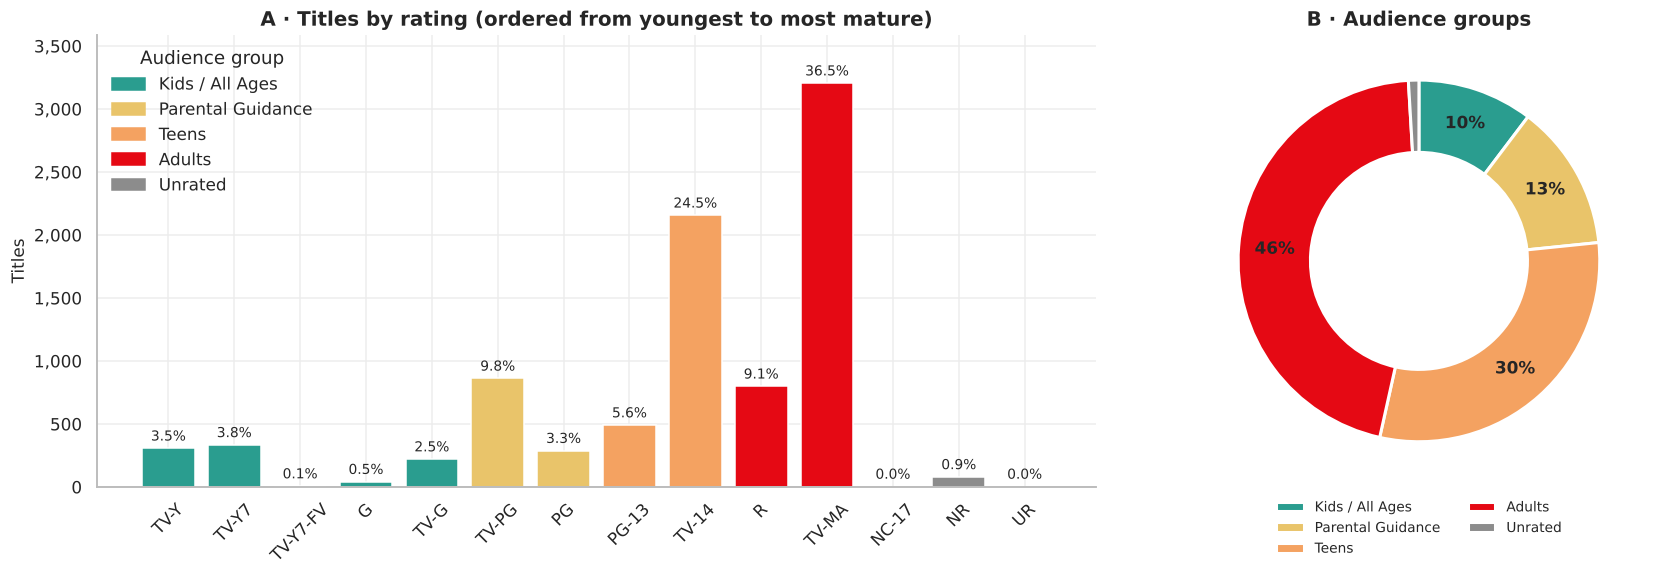

In [47]:
AUD_COLORS = {"Kids / All Ages": "#2A9D8F", "Parental Guidance": "#E9C46A", "Teens": "#F4A261", "Adults": RED, "Unrated": GREY}

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
bars = ax.bar(rating_tbl["Rating"].astype(str), rating_tbl["Titles"], color=[AUD_COLORS[g] for g in rating_tbl["Audience group"]])
ax.bar_label(bars, labels=[f"{s:.1%}" for s in rating_tbl["Share"]], padding=3, fontsize=9)
ax.set(title="A · Titles by rating (ordered from youngest to most mature)", ylabel="Titles", ylim=(0, rating_tbl["Titles"].max() * 1.12))
ax.tick_params(axis="x", rotation=45)
thousands(ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in AUD_COLORS.values()]
ax.legend(handles, AUD_COLORS.keys(), title="Audience group", loc="upper left")

ax = axes[1]
ax.pie(audience.values, colors=[AUD_COLORS[g] for g in audience.index], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2),
       autopct=lambda p: f"{p:.0f}%" if p >= 3 else "", pctdistance=0.8, textprops=dict(fontweight="bold", fontsize=11))
ax.set_title("B · Audience groups")
ax.legend(audience.index, loc="lower center", bbox_to_anchor=(0.5, -0.18), ncol=2, fontsize=9)
fig.tight_layout()
save_fig(fig, "task5_rating_distribution")
plt.show()

## Step 2 · Identify the most common genres

Netflix uses **42 genre tags**, but many are format-specific duplicates (`Dramas` for movies vs `TV Dramas` for series). To compare genres *across* Movies and TV Shows, the tags are mapped into a **unified genre taxonomy**. Both views are shown.

In [48]:
GENRE_UNIFY = {
    "Action & Adventure": "Action & Adventure", "TV Action & Adventure": "Action & Adventure",
    "Anime Features": "Anime", "Anime Series": "Anime",
    "Classic & Cult TV": "Classic & Cult", "Classic Movies": "Classic & Cult", "Cult Movies": "Classic & Cult",
    "Comedies": "Comedy", "TV Comedies": "Comedy",
    "Crime TV Shows": "Crime",
    "Documentaries": "Documentary", "Docuseries": "Documentary",
    "Dramas": "Drama", "TV Dramas": "Drama",
    "Faith & Spirituality": "Faith & Spirituality",
    "Horror Movies": "Horror", "TV Horror": "Horror",
    "Independent Movies": "Independent",
    "International Movies": "International", "International TV Shows": "International",
    "British TV Shows": "International", "Korean TV Shows": "International", "Spanish-Language TV Shows": "International",
    "Children & Family Movies": "Kids & Family", "Kids' TV": "Kids & Family",
    "Teen TV Shows": "Teen",
    "LGBTQ Movies": "LGBTQ",
    "Music & Musicals": "Music & Musicals",
    "TV Mysteries": "Mystery",
    "Reality TV": "Reality",
    "Romantic Movies": "Romance", "Romantic TV Shows": "Romance",
    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy", "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "Science & Nature TV": "Science & Nature",
    "Sports Movies": "Sports",
    "Stand-Up Comedy": "Stand-Up & Talk", "Stand-Up Comedy & Talk Shows": "Stand-Up & Talk",
    "Thrillers": "Thriller", "TV Thrillers": "Thriller",
    "Movies": "Other", "TV Shows": "Other",
}

genre_raw = (df[["show_id", "type", "audience_group", "maturity_level", "year_added", "country_reliable", "listed_in"]]
             .assign(tag=df["listed_in"].str.split(",")).explode("tag").reset_index(drop=True))
genre_raw["tag"] = genre_raw["tag"].str.strip()
unmapped = sorted(set(genre_raw["tag"]) - set(GENRE_UNIFY))
print("Tags missing from the taxonomy:", unmapped or "none")

genre_u = genre_raw.assign(genre=genre_raw["tag"].map(GENRE_UNIFY).fillna("Other"))
genre_u = genre_u.drop_duplicates(["show_id", "genre"]).reset_index(drop=True)            # a title counts once per unified genre
genre_u_main = genre_u[genre_u["genre"] != "Other"].reset_index(drop=True)
print(f"{genre_raw['tag'].nunique()} raw tags -> {genre_u['genre'].nunique()} unified genres")

Tags missing from the taxonomy: none
42 raw tags -> 24 unified genres


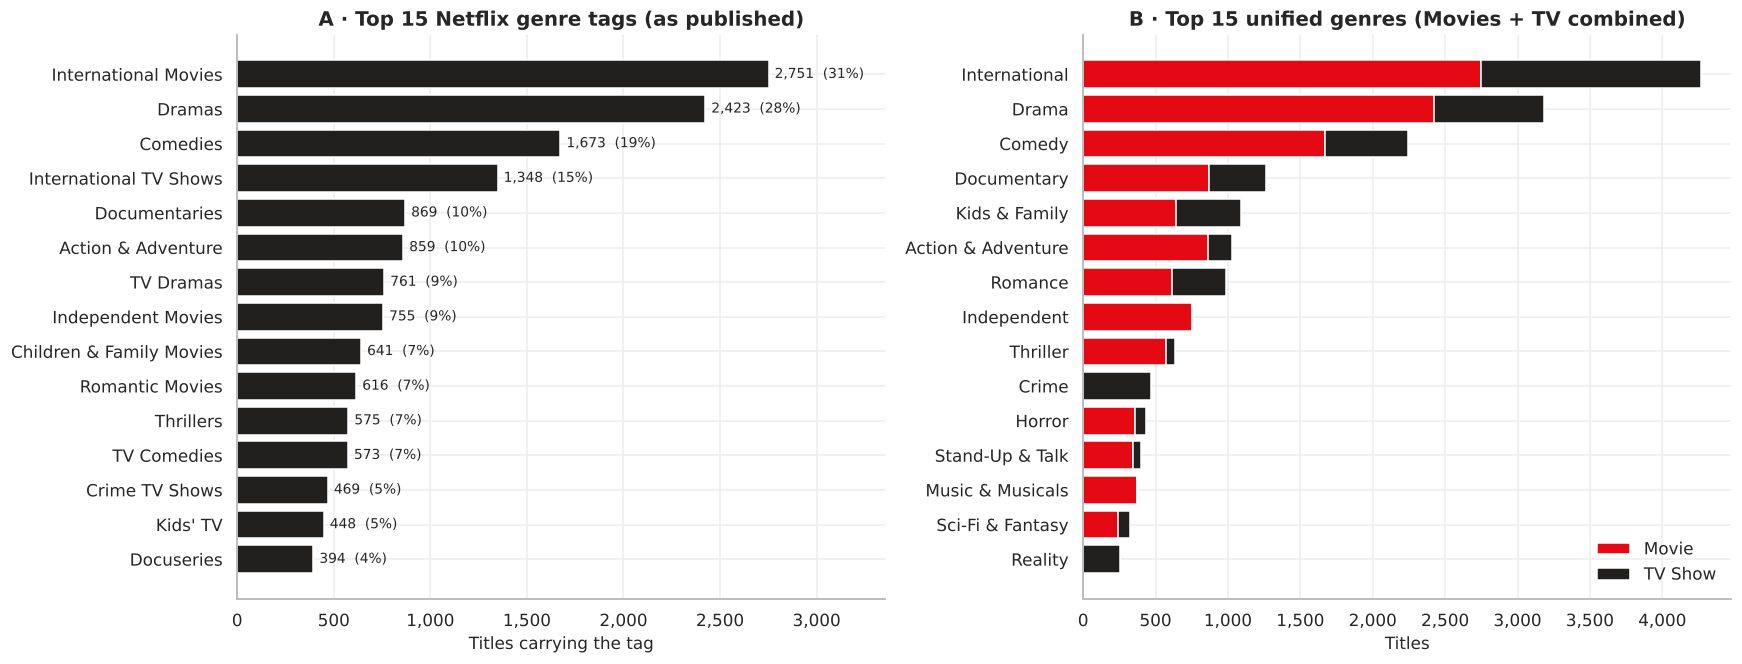

In [49]:
raw_top = genre_raw["tag"].value_counts().head(15)
uni = genre_u_main.groupby("genre").size().sort_values(ascending=False)
uni_type = pd.crosstab(genre_u_main["genre"], genre_u_main["type"]).reindex(columns=TYPE_ORDER, fill_value=0).loc[uni.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
ax = axes[0]
s = raw_top.iloc[::-1]
bars = ax.barh(s.index, s.values, color=DARK)
ax.bar_label(bars, labels=[f"{v:,}  ({v / len(df):.0%})" for v in s.values], padding=4, fontsize=9)
ax.set(title="A · Top 15 Netflix genre tags (as published)", xlabel="Titles carrying the tag", xlim=(0, s.max() * 1.22))
thousands(ax, "x")

ax = axes[1]
u = uni_type.head(15).iloc[::-1]
ax.barh(u.index, u["Movie"], color=RED, label="Movie")
ax.barh(u.index, u["TV Show"], left=u["Movie"], color=DARK, label="TV Show")
ax.set(title="B · Top 15 unified genres (Movies + TV combined)", xlabel="Titles")
thousands(ax, "x")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "task5_top_genres")
plt.show()

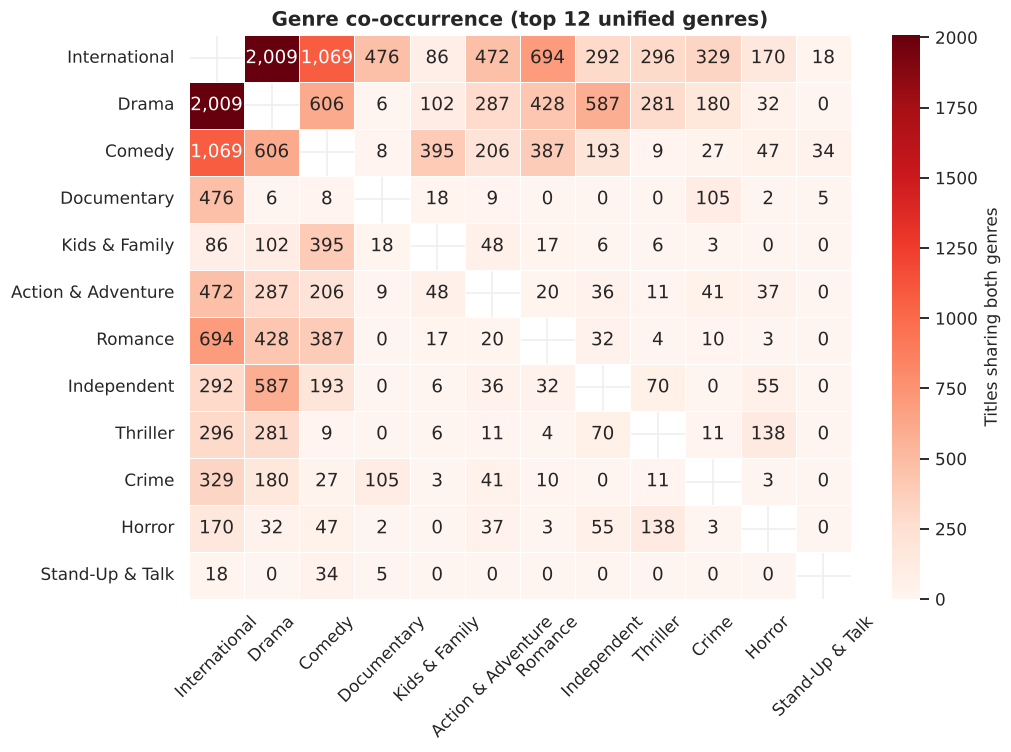

Genre A,Genre B,Titles,Lift
International,Drama,"2,009",1.30
International,Comedy,"1,069",0.98
International,Romance,694,1.45
Drama,Comedy,606,0.74
Drama,Independent,587,2.15
International,Documentary,476,0.78
International,Action & Adventure,472,0.95
Drama,Romance,428,1.20


In [50]:
# Genre combinations: which genres are commonly paired? ------------------------------------------
top_genres = uni.head(12).index.tolist()
mh = pd.crosstab(genre_u_main["show_id"], genre_u_main["genre"])[top_genres].clip(upper=1)
co = mh.T.dot(mh)
n_titles = len(df)
pairs = []
for i, a in enumerate(top_genres):
    for b in top_genres[i + 1:]:
        n_ab = int(co.loc[a, b])
        lift = (n_ab / n_titles) / ((mh[a].sum() / n_titles) * (mh[b].sum() / n_titles))
        pairs.append({"Genre A": a, "Genre B": b, "Titles": n_ab, "Lift": lift})
pairs = pd.DataFrame(pairs).sort_values("Titles", ascending=False)

fig, ax = plt.subplots(figsize=(9.5, 7))
mask = np.eye(len(top_genres), dtype=bool)
sns.heatmap(co, mask=mask, cmap="Reds", annot=True, fmt=",d", linewidths=0.5, linecolor="white", cbar_kws={"label": "Titles sharing both genres"}, ax=ax)
ax.set(title="Genre co-occurrence (top 12 unified genres)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
save_fig(fig, "task5_genre_cooccurrence")
plt.show()
display(pairs.head(8).style.hide(axis="index").format({"Titles": "{:,.0f}", "Lift": "{:.2f}"})
        .set_caption("Most frequent genre pairs (lift > 1 means they appear together more often than chance)"))

## Step 3 · Compare ratings across content types

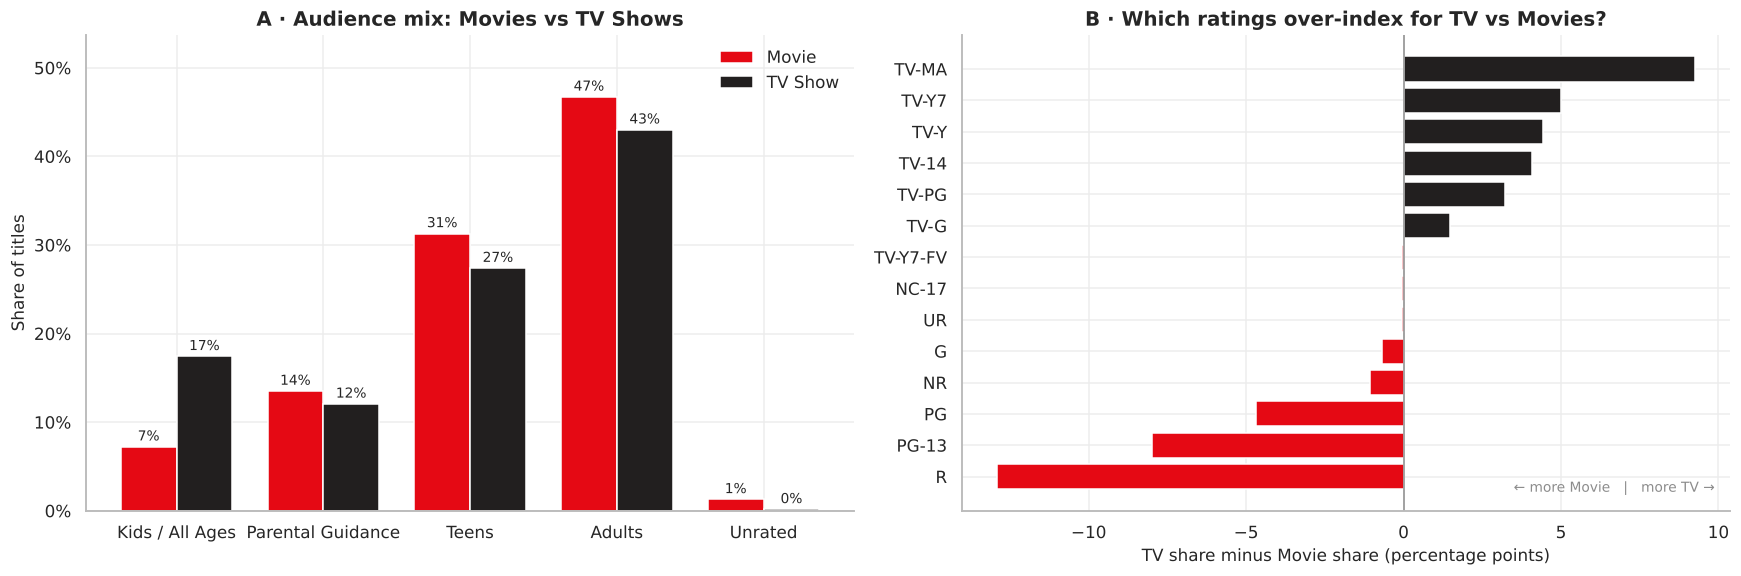

Chi-square test of independence (type × audience group): χ²(4) = 230.6, p = 9.76e-49, Cramér's V = 0.162
Mean maturity level (1 = kids … 4 = adults): Movies 3.19 vs TV 2.96; Mann–Whitney U p = 8.54e-14; rank-biserial r = -0.094


In [51]:
aud_by_type = pd.crosstab(df["type"], df["audience_group"], normalize="index").reindex(TYPE_ORDER)[AUDIENCE_ORDER]
aud_counts = pd.crosstab(df["type"], df["audience_group"]).reindex(TYPE_ORDER)[AUDIENCE_ORDER]

# Statistical tests ---------------------------------------------------------------------------
chi2, chi_p, dof, _ = stats.chi2_contingency(aud_counts)
cramers_v = np.sqrt(chi2 / (aud_counts.values.sum() * (min(aud_counts.shape) - 1)))

mov_lvl = df.loc[(df["type"] == "Movie") & df["maturity_level"].notna(), "maturity_level"]
tv_lvl = df.loc[(df["type"] == "TV Show") & df["maturity_level"].notna(), "maturity_level"]
u_stat, u_p = stats.mannwhitneyu(mov_lvl, tv_lvl, alternative="two-sided")
rank_biserial = 1 - 2 * u_stat / (len(mov_lvl) * len(tv_lvl))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.4))
ax = axes[0]
w = 0.38
xpos = np.arange(len(AUDIENCE_ORDER))
for k, t in enumerate(TYPE_ORDER):
    b = ax.bar(xpos + (k - 0.5) * w, aud_by_type.loc[t].values, width=w, color=TYPE_COLORS[t], label=t)
    ax.bar_label(b, labels=[f"{v:.0%}" for v in aud_by_type.loc[t].values], padding=2, fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(AUDIENCE_ORDER)
ax.set(title="A · Audience mix: Movies vs TV Shows", ylabel="Share of titles", ylim=(0, aud_by_type.values.max() * 1.15))
percent_axis(ax)
ax.legend()

ax = axes[1]
code_share = pd.crosstab(df["rating"], df["type"], normalize="columns").reindex(columns=TYPE_ORDER)
diff = (code_share["TV Show"] - code_share["Movie"]).sort_values()
ax.barh(diff.index.astype(str), diff.values * 100, color=[DARK if v > 0 else RED for v in diff.values])
ax.axvline(0, color=GREY, lw=1)
ax.set(title="B · Which ratings over-index for TV vs Movies?", xlabel="TV share minus Movie share (percentage points)")
ax.text(0.98, 0.04, "← more Movie   |   more TV →", transform=ax.transAxes, ha="right", fontsize=9, color=GREY)
fig.tight_layout()
save_fig(fig, "task5_ratings_by_type")
plt.show()

print(f"Chi-square test of independence (type × audience group): χ²({dof}) = {chi2:,.1f}, p = {chi_p:.3g}, Cramér's V = {cramers_v:.3f}")
print(f"Mean maturity level (1 = kids … 4 = adults): Movies {mov_lvl.mean():.2f} vs TV {tv_lvl.mean():.2f}; Mann–Whitney U p = {u_p:.3g}; rank-biserial r = {rank_biserial:+.3f}")

## Step 4 · Interactive visualisations

*These charts are interactive: hover for exact values, click legend items / segments to filter or drill down, and use the buttons on the genre chart. Run the notebook in Jupyter, VS Code or Colab to enable interactivity.*

In [52]:
# (1) Sunburst: Type -> Audience group -> Rating ----------------------------------------------
sb = (df.groupby(["type", "audience_group", "rating"], observed=True).size().rename("titles").reset_index())
sb[["audience_group", "rating"]] = sb[["audience_group", "rating"]].astype(str)
fig = px.sunburst(sb, path=["type", "audience_group", "rating"], values="titles", color="type",
                  color_discrete_map={"Movie": RED, "TV Show": DARK, "(?)": GREY},
                  title="Content by type → audience group → rating (click a segment to drill down)")
fig.update_traces(hovertemplate="<b>%{label}</b><br>%{value:,} titles<br>%{percentParent:.1%} of parent<extra></extra>",
                  textinfo="label+percent root", insidetextorientation="radial")
fig.update_layout(height=620, margin=dict(l=10, r=10, t=60, b=10))
fig.show()

In [53]:
# (2) Heatmap: unified genre × audience group (row percentages) --------------------------------------
gm = genre_u_main.merge(df[["show_id"]], on="show_id")
gcount = pd.crosstab(gm["genre"], gm["audience_group"])[AUDIENCE_ORDER]
gcount = gcount[gcount.sum(axis=1) >= 100]
gpct = gcount.div(gcount.sum(axis=1), axis=0).sort_values("Adults")

fig = px.imshow(gpct, x=AUDIENCE_ORDER, y=gpct.index, text_auto=".0%", aspect="auto",
                color_continuous_scale="Reds", zmin=0, zmax=0.8,
                title="Who is each genre made for? (share of a genre's titles by audience group)")
fig.update_traces(customdata=gcount.loc[gpct.index].values,
                  hovertemplate="<b>%{y}</b> · %{x}<br>%{z:.1%} of the genre<br>%{customdata:,} titles<extra></extra>")
fig.update_layout(height=700, xaxis_title="", yaxis_title="", coloraxis_colorbar=dict(title="Share", tickformat=".0%"))
fig.show()

In [54]:
# (3) Genre popularity with a Movie / TV / All switch ---------------------------------------------------
views = {
    "All titles": uni.head(12),
    "Movies only": genre_u_main[genre_u_main["type"] == "Movie"].groupby("genre").size().sort_values(ascending=False).head(12),
    "TV Shows only": genre_u_main[genre_u_main["type"] == "TV Show"].groupby("genre").size().sort_values(ascending=False).head(12),
}
view_colors = [BLUE, RED, DARK]
fig = go.Figure()
buttons = []
for i, (label, ser) in enumerate(views.items()):
    ser = ser.iloc[::-1]
    fig.add_trace(go.Bar(y=ser.index, x=ser.values, orientation="h", name=label, visible=(i == 0),
                         marker_color=view_colors[i], text=[f"{v:,}" for v in ser.values], textposition="outside",
                         hovertemplate="<b>%{y}</b><br>%{x:,} titles<extra></extra>"))
    buttons.append(dict(label=label, method="update",
                        args=[{"visible": [j == i for j in range(len(views))]},
                              {"yaxis.categoryorder": "array", "yaxis.categoryarray": list(ser.index),
                               "title.text": f"Top 12 genres — {label}"}]))
fig.update_layout(title="Top 12 genres — All titles", height=560, showlegend=False, xaxis_title="Titles", yaxis_title="",
                  yaxis=dict(categoryorder="array", categoryarray=list(views["All titles"].iloc[::-1].index)),
                  updatemenus=[dict(type="buttons", direction="right", x=0.0, y=1.14, xanchor="left", buttons=buttons)],
                  margin=dict(t=100))
fig.show()

In [55]:
# (4) Treemap: genre size coloured by how adult-oriented it is --------------------------------------------
tm = (genre_u_main.assign(is_adult=genre_u_main["audience_group"].eq("Adults"))
      .groupby("genre").agg(titles=("show_id", "size"), adult_share=("is_adult", "mean")).reset_index())
fig = px.treemap(tm, path=[px.Constant("All genres"), "genre"], values="titles", color="adult_share",
                 color_continuous_scale="RdYlBu_r", range_color=(0, 0.8),
                 title="Genre size (area) and adult orientation (colour = share rated TV-MA / R / NC-17)")
fig.update_traces(hovertemplate="<b>%{label}</b><br>%{value:,} titles<br>Adult share: %{color:.0%}<extra></extra>",
                  texttemplate="<b>%{label}</b><br>%{value:,}")
fig.update_layout(height=560, margin=dict(l=10, r=10, t=60, b=10), coloraxis_colorbar=dict(title="Adult share", tickformat=".0%"))
fig.show()

## Step 5 · Audience insights

In [56]:
# Top genres per audience group -----------------------------------------------------------------
rows = {}
for grp in AUDIENCE_ORDER[:4]:
    sub = genre_u_main[genre_u_main["audience_group"] == grp]
    n_grp = sub["show_id"].nunique()
    top = sub.groupby("genre").size().sort_values(ascending=False).head(5)
    rows[grp] = [f"{g} ({v / n_grp:.0%})" for g, v in top.items()]
top_by_aud = pd.DataFrame(rows, index=[f"#{i}" for i in range(1, 6)])
display(top_by_aud.style.set_caption("Top 5 unified genres per audience group (% of that group's titles)"))

,Kids / All Ages,Parental Guidance,Teens,Adults
#1,Kids & Family (84%),International (42%),International (61%),International (50%)
#2,Comedy (25%),Comedy (32%),Drama (44%),Drama (41%)
#3,International (16%),Kids & Family (28%),Comedy (29%),Comedy (22%)
#4,Documentary (9%),Drama (28%),Romance (18%),Independent (14%)
#5,Drama (5%),Documentary (25%),Action & Adventure (15%),Documentary (13%)


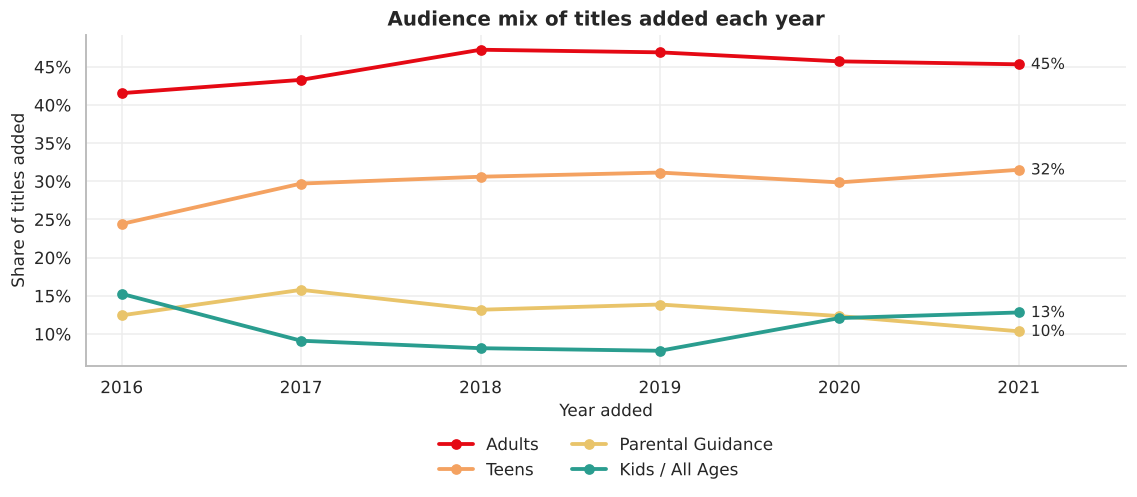

In [57]:
# Maturity trend over time -------------------------------------------------------------------------------
aud_year = (pd.crosstab(df["year_added"], df["audience_group"], normalize="index")[AUDIENCE_ORDER]
            .loc[2016:])
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for grp in ["Adults", "Teens", "Parental Guidance", "Kids / All Ages"]:
    ax.plot(aud_year.index, aud_year[grp], marker="o", lw=2.5, color=AUD_COLORS[grp], label=grp)
    ax.annotate(f"{aud_year[grp].iloc[-1]:.0%}", (aud_year.index[-1], aud_year[grp].iloc[-1]), textcoords="offset points", xytext=(8, -3), fontsize=10)
ax.set(title="Audience mix of titles added each year", xlabel="Year added", ylabel="Share of titles added", xlim=(2015.8, aud_year.index[-1] + 0.6))
percent_axis(ax)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.17))
fig.tight_layout()
save_fig(fig, "task5_audience_trend")
plt.show()

In [58]:
adult_share_all = (df["audience_group"] == "Adults").mean()
teen_share_all = (df["audience_group"] == "Teens").mean()
kids_share_all = (df["audience_group"] == "Kids / All Ages").mean()
older_share = adult_share_all + teen_share_all
adult_first, adult_last = aud_year["Adults"].iloc[0], aud_year["Adults"].iloc[-1]
most_adult = gpct["Adults"].sort_values(ascending=False).head(3)
kids_by_genre = gcount.div(gcount.sum(axis=1), axis=0)["Kids / All Ages"].sort_values(ascending=False)
most_kids = kids_by_genre[kids_by_genre >= 0.20]
aud_diff = (aud_by_type.loc["TV Show"] - aud_by_type.loc["Movie"]).drop("Unrated")
tv_over, mov_over = aud_diff.idxmax(), aud_diff.idxmin()
top_rating = df["rating"].value_counts().idxmax()
top_rating_n = int(df["rating"].value_counts().max())
top_pair = pairs.iloc[0]
tvma = int((df["rating"] == "TV-MA").sum())
effect = "negligible" if cramers_v < 0.1 else ("small" if cramers_v < 0.3 else ("medium" if cramers_v < 0.5 else "large"))
tv_more = "TV shows" if tv_lvl.mean() > mov_lvl.mean() else "Movies"

md(f"""
### Task 5 · Audience insights

1. **Netflix targets older audiences.** **{adult_share_all:.0%}** of titles are adult-rated (TV-MA / R / NC-17) and a further **{teen_share_all:.0%}** are teen-rated, so about **{older_share:.0%}** of the catalog is aimed at teens and adults; children and all-ages content is **{kids_share_all:.0%}**. **{top_rating} alone is the single largest rating ({top_rating_n:,} titles, {top_rating_n / len(df):.0%}).**
2. **The adult share {trend_word(adult_first, adult_last, 0.03)} over time** — from **{adult_first:.0%}** of titles added in {aud_year.index[0]} to **{adult_last:.0%}** in {aud_year.index[-1]}.
3. **Movies and TV shows are rated differently, but the effect is {effect}.** The chi-square test is {'significant' if chi_p < 0.05 else 'not significant'} (p = {chi_p:.3g}) with Cramér's V = {cramers_v:.2f}; on the 1–4 maturity scale **{tv_more}** are slightly more mature (Movies {mov_lvl.mean():.2f} vs TV {tv_lvl.mean():.2f}; Mann–Whitney p = {u_p:.3g}). Relative to movies, TV shows over-index on **{tv_over}** ({aud_diff[tv_over] * 100:+.0f} pp) and movies over-index on **{mov_over}** ({-aud_diff[mov_over] * 100:+.0f} pp).
4. **Most common genres.** The largest unified genres are **{', '.join(uni.index[:5])}**. *International* content alone appears in **{uni['International'] / len(df):.0%}** of titles, confirming that international content is central to the catalog, not a niche.
5. **Genres have clear audiences.** The most adult-oriented genres (≥ 100 titles) are **{', '.join(f'{g} ({v:.0%})' for g, v in most_adult.items())}**; {('kids / all-ages content is a meaningful share of only: **' + ', '.join(f'{g} ({v:.0%})' for g, v in most_kids.items()) + '**.') if len(most_kids) else 'no genre has a meaningful kids / all-ages share.'}
6. **Genres are rarely stand-alone.** The most frequent pairing is **{top_pair['Genre A']} + {top_pair['Genre B']}** ({int(top_pair['Titles']):,} titles). Titles carry {df['n_genres'].mean():.1f} genre tags on average, so recommendation and marketing should use genre *combinations*, not single labels.

**Business interpretation:** the catalog is built primarily for teen and adult viewers. Kids / all-ages content is the thinnest segment ({kids_share_all:.0%} of titles) and is concentrated in very few genres, so it is the clearest candidate if the business wants to broaden household appeal; adult-skewed genres such as {most_adult.index[0]} and {most_adult.index[1]} are the catalog's strongest fit for individual adult viewers.
""")


### Task 5 · Audience insights

1. **Netflix targets older audiences.** **46%** of titles are adult-rated (TV-MA / R / NC-17) and a further **30%** are teen-rated, so about **76%** of the catalog is aimed at teens and adults; children and all-ages content is **10%**. **TV-MA alone is the single largest rating (3,204 titles, 36%).**
2. **The adult share rose over time** — from **42%** of titles added in 2016 to **45%** in 2021.
3. **Movies and TV shows are rated differently, but the effect is small.** The chi-square test is significant (p = 9.76e-49) with Cramér's V = 0.16; on the 1–4 maturity scale **Movies** are slightly more mature (Movies 3.19 vs TV 2.96; Mann–Whitney p = 8.54e-14). Relative to movies, TV shows over-index on **Kids / All Ages** (+10 pp) and movies over-index on **Teens** (+4 pp).
4. **Most common genres.** The largest unified genres are **International, Drama, Comedy, Documentary, Kids & Family**. *International* content alone appears in **49%** of titles, confirming that international content is central to the catalog, not a niche.
5. **Genres have clear audiences.** The most adult-oriented genres (≥ 100 titles) are **Stand-Up & Talk (84%), Crime (75%), Horror (72%)**; kids / all-ages content is a meaningful share of only: **Kids & Family (68%)**.
6. **Genres are rarely stand-alone.** The most frequent pairing is **International + Drama** (2,009 titles). Titles carry 2.2 genre tags on average, so recommendation and marketing should use genre *combinations*, not single labels.

**Business interpretation:** the catalog is built primarily for teen and adult viewers. Kids / all-ages content is the thinnest segment (10% of titles) and is concentrated in very few genres, so it is the clearest candidate if the business wants to broaden household appeal; adult-skewed genres such as Stand-Up & Talk and Crime are the catalog's strongest fit for individual adult viewers.


<a id="task6"></a>

---

# Task 6 · Netflix Business Insights Report  `Advanced`

**Goal:** create a comprehensive business-intelligence report from the Netflix dataset.

| Step | Activity |
|------|----------|
| 1 | Perform a complete exploratory data analysis (EDA) |
| 2 | Identify key content trends and patterns |
| 3 | Develop multiple visual dashboards |
| 4 | Generate actionable business insights |
| 5 | Prepare and present the final analytical report |

## Step 1 · Complete exploratory data analysis

### 1.1 Dataset snapshot

In [59]:
known_country_mask = ~df["country_reliable"].isin(NON_COUNTRY)
snapshot = pd.DataFrame({
    "Metric": [
        "Titles (after cleaning)", "Movies", "TV shows", "Release years covered", "Titles added between",
        "Countries with a reliable label", "Unified genres (from 42 raw tags)", "Distinct rating codes",
        "Titles with a named director", "Titles with a reliable country",
    ],
    "Value": [
        f"{len(df):,}", f"{movie_n:,} ({movie_n / len(df):.1%})", f"{tv_n:,} ({tv_n / len(df):.1%})",
        f"{df['release_year'].min()} – {df['release_year'].max()}",
        f"{df['date_added'].min():%b %Y} – {df['date_added'].max():%b %Y}",
        f"{df.loc[known_country_mask, 'country_reliable'].nunique()}",
        f"{genre_u_main['genre'].nunique()}", f"{df['rating'].nunique()}",
        f"{(df['director'] != 'Unknown').mean():.1%}", f"{known_country_mask.mean():.1%}",
    ],
})
display(snapshot.style.hide(axis="index").set_caption("Dataset snapshot"))

Metric,Value
Titles (after cleaning),"8,786"
Movies,"6,123 (69.7%)"
TV shows,"2,663 (30.3%)"
Release years covered,1925 – 2021
Titles added between,Jan 2008 – Sep 2021
Countries with a reliable label,85
Unified genres (from 42 raw tags),23
Distinct rating codes,14
Titles with a named director,70.6%
Titles with a reliable country,92.2%


### 1.2 Numeric profile

In [60]:
num_cols = ["release_year", "year_added", "lag_years", "duration_min", "n_seasons", "n_genres"]
desc = df[num_cols].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["skew"] = df[num_cols].skew()
display(desc.style.format("{:,.2f}").set_caption("Descriptive statistics (duration_min = movies only, n_seasons = TV shows only)"))

mv = df.loc[df["type"] == "Movie", "duration_min"]
q1, q3 = mv.quantile([0.25, 0.75])
iqr_low, iqr_high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
n_out = int(((mv < iqr_low) | (mv > iqr_high)).sum())
print(f"Movie runtime outliers (IQR rule: < {iqr_low:.0f} or > {iqr_high:.0f} min): {n_out} titles ({n_out / len(mv):.1%}) — retained; they are plausible shorts and long-form films.")

,count,mean,std,min,25%,50%,75%,max,skew
release_year,"8,786.00","2,014.18",8.83,"1,925.00","2,013.00","2,017.00","2,019.00","2,021.00",-3.45
year_added,"8,786.00","2,018.87",1.57,"2,008.00","2,018.00","2,019.00","2,020.00","2,021.00",-0.71
lag_years,"8,786.00",4.69,8.79,-3.00,0.00,1.00,5.00,93.00,3.51
duration_min,"6,123.00",99.57,28.28,3.00,87.00,98.00,114.00,312.00,0.20
n_seasons,"2,663.00",1.75,1.55,1.00,1.00,1.00,2.00,17.00,3.39
n_genres,"8,786.00",2.19,0.78,1.00,2.00,2.00,3.00,3.00,-0.36


Movie runtime outliers (IQR rule: < 46 or > 154 min): 449 titles (7.3%) — retained; they are plausible shorts and long-form films.


### 1.3 Categorical profile

In [61]:
cat_rows = []
for col in ["type", "country_reliable", "rating", "audience_group", "director"]:
    vc = df.loc[~df[col].isin(["Unknown", "Unverified"]), col].value_counts()
    cat_rows.append({"Column": col, "Distinct values": vc.size, "Most common": str(vc.index[0]),
                     "Share of known values": vc.iloc[0] / vc.sum()})
display(pd.DataFrame(cat_rows).style.hide(axis="index").format({"Share of known values": "{:.1%}"})
        .set_caption("Categorical overview (Unknown / Unverified excluded)"))

# Director analysis -------------------------------------------------------------------------------
dir_df = (df.loc[df["director"] != "Unknown", ["show_id", "type", "director"]]
          .assign(d=lambda x: x["director"].str.split(","))
          .explode("d").assign(d=lambda x: x["d"].str.strip()).reset_index(drop=True))
top_dir = dir_df.groupby("d").agg(titles=("show_id", "nunique"), tv_share=("type", lambda s: (s == "TV Show").mean())) \
                .sort_values("titles", ascending=False).head(10)
n_dir = dir_df["d"].nunique()
repeat_share = (dir_df.groupby("d")["show_id"].nunique() > 1).mean()
display(top_dir.style.format({"titles": "{:,.0f}", "tv_share": "{:.0%}"}).set_caption(f"Top 10 directors ({n_dir:,} distinct directors named)"))
print(f"Directors with more than one title: {repeat_share:.1%} — the catalog is mostly one-off directors; no single director dominates.")

Column,Distinct values,Most common,Share of known values
type,2,Movie,69.7%
country_reliable,85,United States,40.0%
rating,14,TV-MA,36.5%
audience_group,5,Adults,45.6%
director,4527,Rajiv Chilaka,0.3%


,titles,tv_share
d,,
Rajiv Chilaka,23,4%
Jan Suter,21,0%
Alastair Fothergill,19,74%
Raúl Campos,19,0%
Suhas Kadav,16,0%
Marcus Raboy,16,6%
Jay Karas,15,0%
Cathy Garcia-Molina,13,0%
Jay Chapman,12,0%


Directors with more than one title: 20.5% — the catalog is mostly one-off directors; no single director dominates.


### 1.4 Relationships between numeric variables

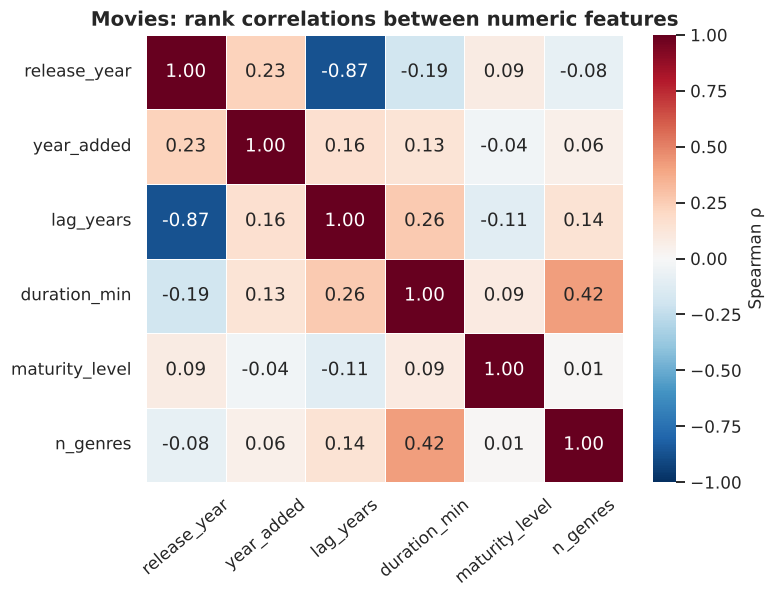

Release year, year added and age-at-addition are linked by construction (lag = year added − release year). Excluding those, the strongest relationship is duration_min vs n_genres (ρ = +0.42).


In [62]:
corr_cols = ["release_year", "year_added", "lag_years", "duration_min", "maturity_level", "n_genres"]
corr = df.loc[df["type"] == "Movie", corr_cols].corr(method="spearman")
mechanical = {frozenset(p) for p in [("release_year", "year_added"), ("release_year", "lag_years"), ("year_added", "lag_years")]}
pairs_c = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr_cols) for b in corr_cols[i + 1:] if frozenset((a, b)) not in mechanical]
strongest = max(pairs_c, key=lambda t: abs(t[2]))

fig, ax = plt.subplots(figsize=(7.2, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor="white", ax=ax,
            cbar_kws={"label": "Spearman ρ"})
ax.set_title("Movies: rank correlations between numeric features")
ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
save_fig(fig, "task6_correlation")
plt.show()
print(f"Release year, year added and age-at-addition are linked by construction (lag = year added − release year). "
      f"Excluding those, the strongest relationship is {strongest[0]} vs {strongest[1]} (ρ = {strongest[2]:+.2f}).")

## Step 2 · Key content trends and patterns

All patterns are computed by **year added**, which describes how the catalog has been built over time. {PARTIAL_YEAR} is a partial year, so its shares are shown but its counts should not be compared with full years.

In [63]:
FIRST_YEAR_TREND = 2016
intl_ids = set(genre_u_main.loc[genre_u_main["genre"] == "International", "show_id"])
df["is_international_genre"] = df["show_id"].isin(intl_ids)

yr = df[df["year_added"] >= FIRST_YEAR_TREND]
known_yr = yr[~yr["country_reliable"].isin(NON_COUNTRY)]
by_year = yr.groupby("year_added").agg(
    titles=("show_id", "size"),
    tv_share=("type", lambda s: (s == "TV Show").mean()),
    adult_share=("audience_group", lambda s: (s == "Adults").mean()),
    kids_share=("audience_group", lambda s: (s == "Kids / All Ages").mean()),
    international_genre=("is_international_genre", "mean"),
    backcatalog=("lag_years", lambda s: (s.clip(lower=0) >= BACKCATALOG_YEARS).mean()),
)
by_year["non_us_share"] = known_yr.groupby("year_added")["country_reliable"].apply(lambda s: (s != "United States").mean())

display(by_year.rename(columns={
    "titles": "Titles added", "tv_share": "TV share", "adult_share": "Adult-rated", "kids_share": "Kids / all-ages",
    "international_genre": "'International' genre", "backcatalog": f"Back-catalog ({BACKCATALOG_YEARS}+ yrs old)", "non_us_share": "Non-US share",
}).style.format({"Titles added": "{:,.0f}", "TV share": "{:.1%}", "Adult-rated": "{:.1%}", "Kids / all-ages": "{:.1%}",
                 "'International' genre": "{:.1%}", f"Back-catalog ({BACKCATALOG_YEARS}+ yrs old)": "{:.1%}", "Non-US share": "{:.1%}"})
        .background_gradient(cmap="Reds", axis=0).set_caption(f"Catalog-building scorecard by year added ({PARTIAL_YEAR} partial)"))

,Titles added,TV share,Adult-rated,Kids / all-ages,'International' genre,Back-catalog (5+ yrs old),Non-US share
year_added,,,,,,,
2016,426,41.1%,41.5%,15.3%,42.3%,18.8%,56.3%
2017,"1,185",29.5%,43.3%,9.1%,53.6%,17.0%,64.0%
2018,"1,647",25.0%,47.2%,8.1%,54.9%,26.4%,66.8%
2019,"2,013",29.4%,46.9%,7.8%,49.0%,29.7%,59.1%
2020,"1,879",31.7%,45.7%,12.1%,46.6%,27.9%,59.8%
2021,"1,498",33.7%,45.3%,12.8%,44.1%,34.7%,54.3%


In [64]:
# Momentum: what gained / lost share between the two halves of the period? ---------------------------------------
early_ids = df.loc[df["year_added"].between(2016, 2018), "show_id"]
late_ids = df.loc[df["year_added"].between(2019, 2021), "show_id"]

g_early = genre_u_main[genre_u_main["show_id"].isin(early_ids)].groupby("genre").size() / len(early_ids)
g_late = genre_u_main[genre_u_main["show_id"].isin(late_ids)].groupby("genre").size() / len(late_ids)
g_total = genre_u_main.groupby("genre").size()
momentum = ((g_late - g_early) * 100).dropna()
momentum = momentum[g_total.reindex(momentum.index) >= 100].sort_values()
gainers, losers = momentum.tail(5).iloc[::-1], momentum.head(5)

ctry = known_yr.assign(period=np.where(known_yr["year_added"] <= 2018, "early", "late"))
ctry_share = pd.crosstab(ctry["country_reliable"], ctry["period"], normalize="columns")
top_ctry = rank.head(8).index
c_mom = ((ctry_share.loc[top_ctry, "late"] - ctry_share.loc[top_ctry, "early"]) * 100).sort_values()

mom_tbl = pd.DataFrame({
    "Genre gaining share": [f"{g}  ({v:+.1f} pp)" for g, v in gainers.items()],
    "Genre losing share": [f"{g}  ({v:+.1f} pp)" for g, v in losers.items()],
    "Country gaining share": [f"{g}  ({v:+.1f} pp)" for g, v in c_mom.tail(5).iloc[::-1].items()],
    "Country losing share": [f"{g}  ({v:+.1f} pp)" for g, v in c_mom.head(5).items()],
}, index=[f"#{i}" for i in range(1, 6)])
display(mom_tbl.style.set_caption("Momentum: share of titles added 2019–21 vs 2016–18 (pp = percentage points)"))

,Genre gaining share,Genre losing share,Country gaining share,Country losing share
#1,Comedy (+5.5 pp),Documentary (-6.1 pp),United States (+6.2 pp),India (-5.1 pp)
#2,Kids & Family (+3.3 pp),International (-6.0 pp),Japan (+0.8 pp),United Kingdom (-2.3 pp)
#3,Action & Adventure (+2.5 pp),Stand-Up & Talk (-3.9 pp),South Korea (+0.1 pp),Canada (-1.0 pp)
#4,Romance (+2.3 pp),Independent (-1.4 pp),France (+0.0 pp),Spain (-0.4 pp)
#5,Reality (+1.7 pp),Music & Musicals (-1.2 pp),Spain (-0.4 pp),France (+0.0 pp)


In [65]:
tv_lo, tv_hi = by_year.loc[2017:, "tv_share"].min(), by_year.loc[2017:, "tv_share"].max()
tv_peak_y = by_year["tv_share"].idxmax()
patterns = f"""
### Patterns identified

* **Format:** TV's share of additions was highest in {tv_peak_y} ({by_year.loc[tv_peak_y, 'tv_share']:.0%}) and has since stayed in a band of {tv_lo:.0%}–{tv_hi:.0%}; the year-by-year path is uneven rather than a steady shift.
* **Geography:** the non-US share of additions {trend_word(by_year['non_us_share'].iloc[0], by_year['non_us_share'].iloc[-1], 0.05)} (from {by_year['non_us_share'].iloc[0]:.0%} to {by_year['non_us_share'].iloc[-1]:.0%}); "International" is now tagged on {by_year['international_genre'].iloc[-1]:.0%} of new titles.
* **Audience:** the adult-rated share {trend_word(by_year['adult_share'].iloc[0], by_year['adult_share'].iloc[-1], 0.03)} from {by_year['adult_share'].iloc[0]:.0%} to {by_year['adult_share'].iloc[-1]:.0%}.
* **Age of content:** back-catalog titles are {by_year['backcatalog'].iloc[-1]:.0%} of {by_year.index[-1]} additions versus {by_year['backcatalog'].iloc[0]:.0%} in {by_year.index[0]}.
* **Genre momentum:** gaining — {', '.join(gainers.index[:3])}; losing — {', '.join(losers.index[:3])}.
* **Country momentum:** among the top 8 countries, gaining — {', '.join(c_mom.tail(3).iloc[::-1].index)}; losing — {', '.join(c_mom.head(3).index)}.
"""
md(patterns)


### Patterns identified

* **Format:** TV's share of additions was highest in 2016 (41%) and has since stayed in a band of 25%–34%; the year-by-year path is uneven rather than a steady shift.
* **Geography:** the non-US share of additions held steady (from 56% to 54%); "International" is now tagged on 44% of new titles.
* **Audience:** the adult-rated share rose from 42% to 45%.
* **Age of content:** back-catalog titles are 35% of 2021 additions versus 19% in 2016.
* **Genre momentum:** gaining — Comedy, Kids & Family, Action & Adventure; losing — Documentary, International, Stand-Up & Talk.
* **Country momentum:** among the top 8 countries, gaining — United States, Japan, South Korea; losing — India, United Kingdom, Canada.


## Step 3 · Visual dashboards

Three dashboards give three views of the same data: **(A) Executive overview**, **(B) Strategy & trends**, **(C) Portfolio deep-dive**. Each is saved as a high-resolution PNG in `outputs/figures/` for reports and screenshots.

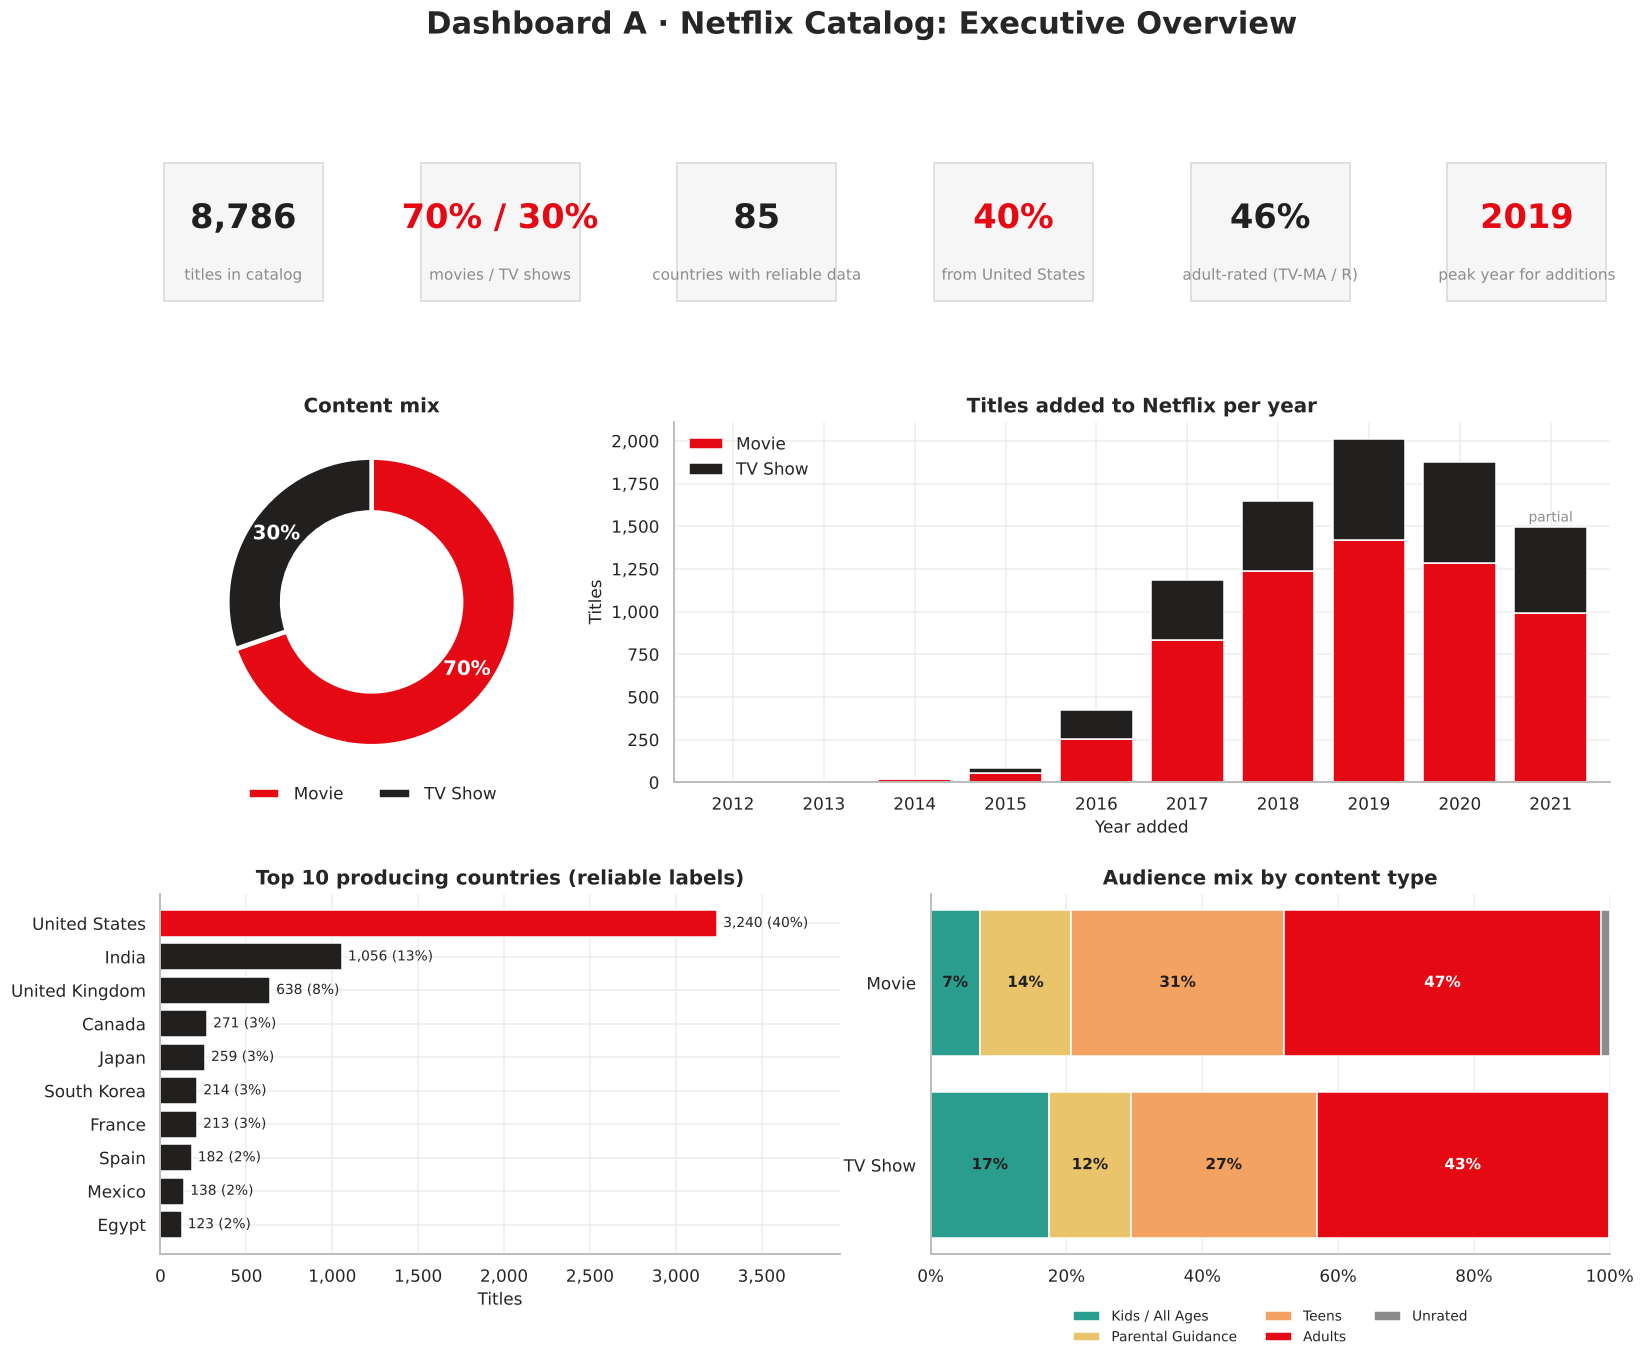

In [66]:
def kpi_tile(ax, value: str, label: str, color: str = DARK) -> None:
    """Draw a KPI card on an empty axes."""
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0.02, 0.06), 0.96, 0.88, transform=ax.transAxes, facecolor="#F6F6F6", edgecolor="#DDDDDD", lw=1.2))
    ax.text(0.5, 0.58, value, ha="center", va="center", fontsize=22, fontweight="bold", color=color)
    ax.text(0.5, 0.22, label, ha="center", va="center", fontsize=10, color=GREY)


# ---------------------------------- Dashboard A: Executive overview ----------------------------------
fig = plt.figure(figsize=(17, 13))
gs = GridSpec(3, 6, figure=fig, height_ratios=[0.5, 1.15, 1.15], hspace=0.38, wspace=0.55)
fig.suptitle("Dashboard A · Netflix Catalog: Executive Overview", fontsize=20, fontweight="bold", y=0.98)

kpis = [
    (f"{len(df):,}", "titles in catalog", DARK),
    (f"{movie_n / len(df):.0%} / {tv_n / len(df):.0%}", "movies / TV shows", RED),
    (f"{rank.shape[0]}", "countries with reliable data", DARK),
    (f"{us_share:.0%}", f"from {rank.index[0]}", RED),
    (f"{adult_share_all:.0%}", "adult-rated (TV-MA / R)", DARK),
    (f"{add_peak_year}", "peak year for additions", RED),
]
for i, (v, lab, col) in enumerate(kpis):
    kpi_tile(fig.add_subplot(gs[0, i]), v, lab, col)

ax = fig.add_subplot(gs[1, 0:2])
ax.pie(type_counts.values, colors=[TYPE_COLORS[t] for t in TYPE_ORDER], startangle=90, counterclock=False,
       wedgeprops=dict(width=0.38, edgecolor="white", linewidth=3), autopct="%1.0f%%", pctdistance=0.81,
       textprops=dict(color="white", fontweight="bold", fontsize=13))
ax.set_title("Content mix")
ax.legend(TYPE_ORDER, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.1))

ax = fig.add_subplot(gs[1, 2:6])
ad = pd.crosstab(df["year_added"], df["type"]).reindex(columns=TYPE_ORDER).loc[2012:]
ad.plot(kind="bar", stacked=True, ax=ax, color=[TYPE_COLORS[t] for t in TYPE_ORDER], width=0.8, legend=False)
ax.set(title="Titles added to Netflix per year", xlabel="Year added", ylabel="Titles")
ax.tick_params(axis="x", rotation=0)
thousands(ax)
ax.legend(TYPE_ORDER, loc="upper left")
if PARTIAL_YEAR in ad.index:
    ax.text(list(ad.index).index(PARTIAL_YEAR), ad.loc[PARTIAL_YEAR].sum() + 30, "partial", ha="center", fontsize=9, color=GREY)

ax = fig.add_subplot(gs[2, 0:3])
t10 = rank.head(10).iloc[::-1]
bars = ax.barh(t10.index, t10["Titles"], color=[RED if c == rank.index[0] else DARK for c in t10.index])
ax.bar_label(bars, labels=[f"{v:,} ({s:.0%})" for v, s in zip(t10["Titles"], t10["Share"])], padding=4, fontsize=9)
ax.set(title="Top 10 producing countries (reliable labels)", xlabel="Titles", xlim=(0, t10["Titles"].max() * 1.22))
thousands(ax, "x")

ax = fig.add_subplot(gs[2, 3:6])
left = np.zeros(len(TYPE_ORDER))
for grp in AUDIENCE_ORDER:
    vals = aud_by_type[grp].values
    ax.barh(TYPE_ORDER, vals, left=left, color=AUD_COLORS[grp], label=grp, edgecolor="white")
    for k, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.06:
            ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=10, fontweight="bold", color="white" if grp in ("Adults", "Unrated") else DARK)
    left += vals
ax.set(title="Audience mix by content type", xlim=(0, 1))
percent_axis(ax, "x")
ax.invert_yaxis()
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=9)

save_fig(fig, "task6_dashboard_A_executive_overview")
plt.show()

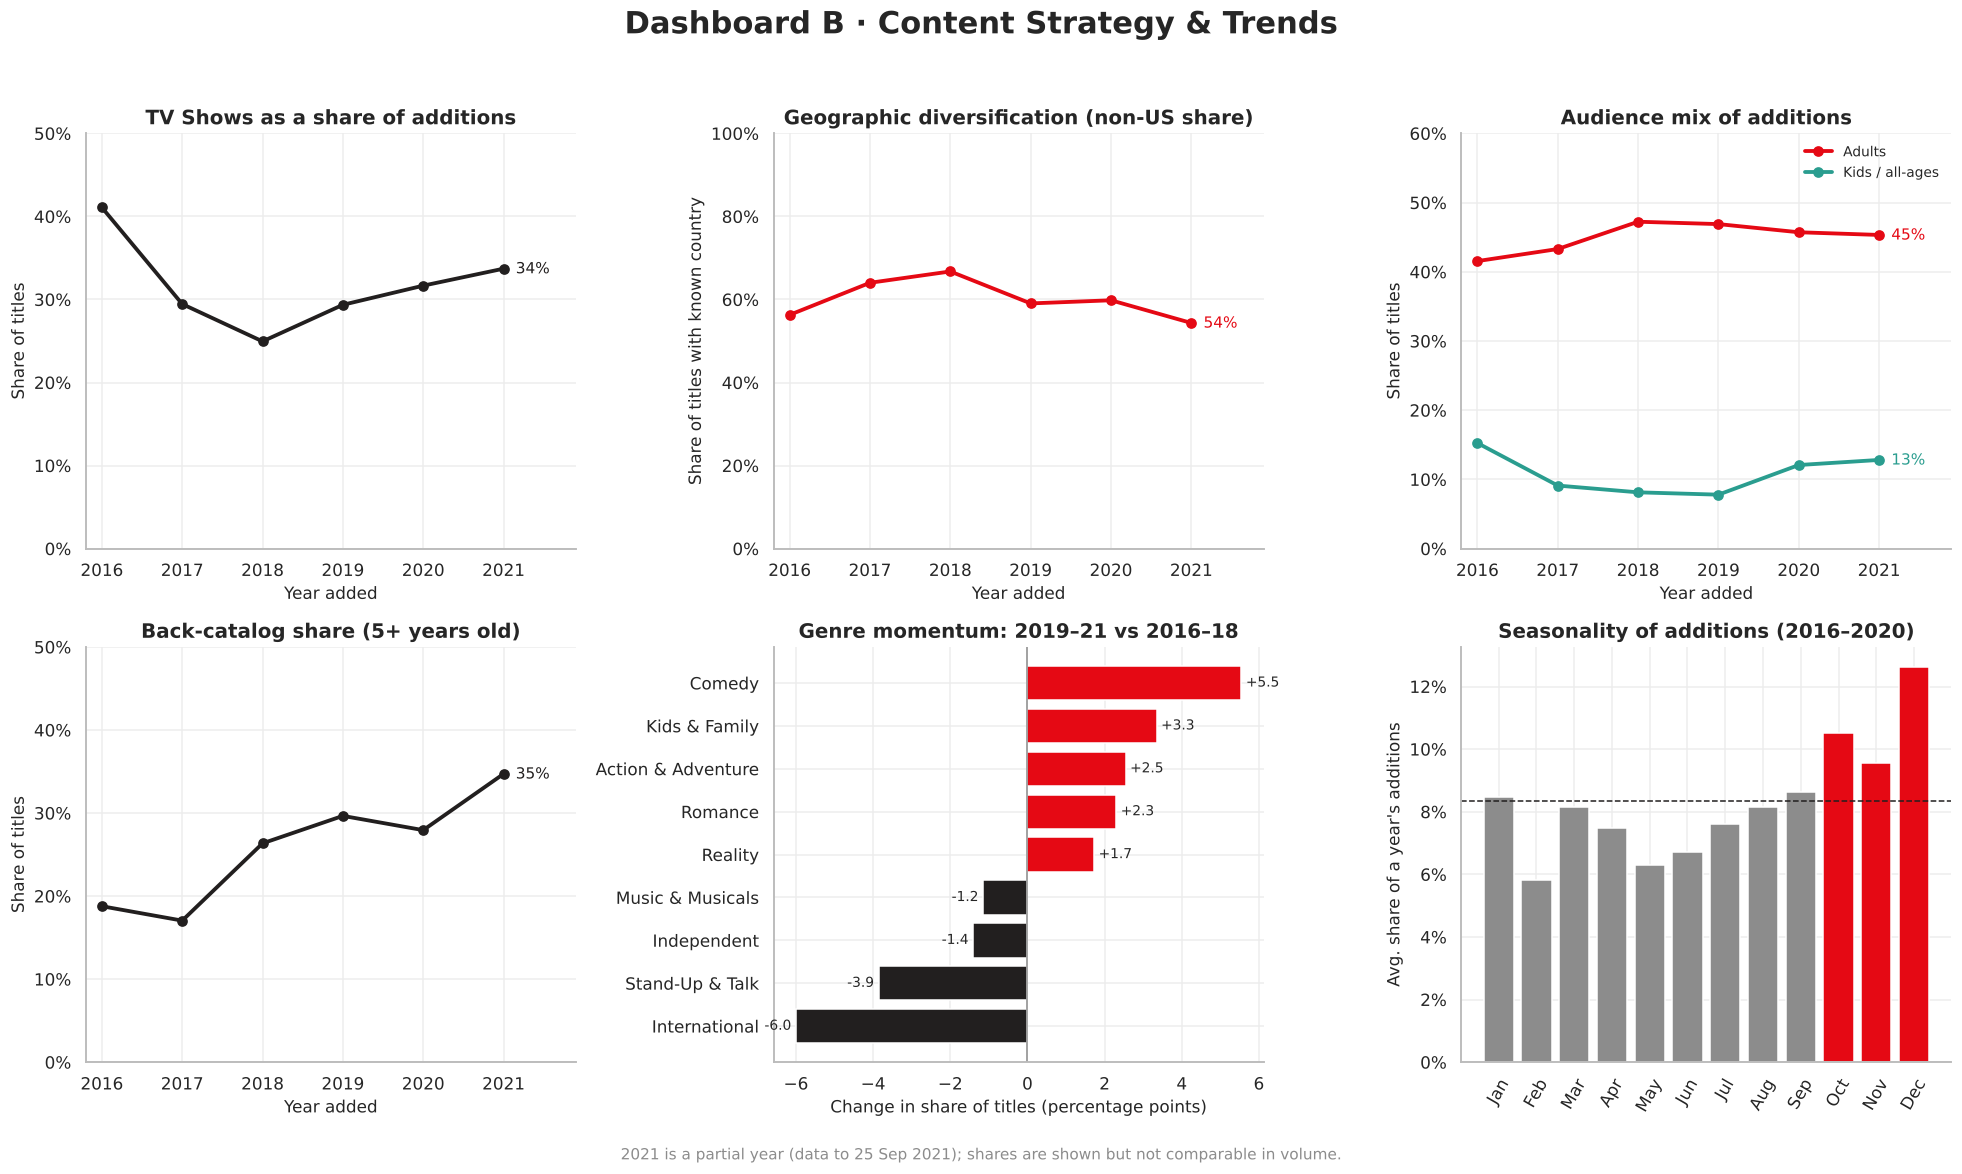

In [67]:
# ---------------------------------- Dashboard B: Strategy & trends ----------------------------------
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
fig.suptitle("Dashboard B · Content Strategy & Trends", fontsize=20, fontweight="bold", y=0.995)
ylab = "Year added"


def line_panel(ax, series_map, title, ylab_text, ylim_top=None):
    """Plot one or more yearly share series with end labels."""
    for name, (ser, col) in series_map.items():
        ax.plot(ser.index, ser.values, marker="o", lw=2.5, color=col, label=name)
        ax.annotate(f"{ser.iloc[-1]:.0%}", (ser.index[-1], ser.iloc[-1]), textcoords="offset points", xytext=(8, -3), fontsize=10, color=col)
    ax.set(title=title, xlabel=ylab, ylabel=ylab_text, xlim=(by_year.index[0] - 0.2, by_year.index[-1] + 0.9))
    if ylim_top:
        ax.set_ylim(0, ylim_top)
    percent_axis(ax)
    ax.xaxis.set_major_locator(mtick.MaxNLocator(integer=True))
    if len(series_map) > 1:
        ax.legend(fontsize=9)


line_panel(axes[0, 0], {"TV share": (by_year["tv_share"], DARK)}, "TV Shows as a share of additions", "Share of titles", 0.5)
line_panel(axes[0, 1], {"Non-US share": (by_year["non_us_share"], RED)}, "Geographic diversification (non-US share)", "Share of titles with known country", 1.0)
line_panel(axes[0, 2], {"Adults": (by_year["adult_share"], RED), "Kids / all-ages": (by_year["kids_share"], "#2A9D8F")},
           "Audience mix of additions", "Share of titles", 0.6)
line_panel(axes[1, 0], {"Back-catalog": (by_year["backcatalog"], DARK)}, f"Back-catalog share ({BACKCATALOG_YEARS}+ years old)", "Share of titles", 0.5)

ax = axes[1, 1]
mm = pd.concat([losers.iloc[::-1].head(4), gainers.head(5)]).sort_values()
ax.barh(mm.index, mm.values, color=[RED if v > 0 else DARK for v in mm.values])
ax.axvline(0, color=GREY, lw=1)
ax.bar_label(ax.containers[0], labels=[f"{v:+.1f}" for v in mm.values], padding=3, fontsize=9)
ax.set(title="Genre momentum: 2019–21 vs 2016–18", xlabel="Change in share of titles (percentage points)")

ax = axes[1, 2]
ax.bar(list(calendar.month_abbr)[1:], avg_month_share.values, color=[RED if m in top_months else GREY for m in avg_month_share.index])
ax.axhline(1 / 12, color=DARK, ls="--", lw=1)
ax.set(title=f"Seasonality of additions ({season_years[0]}–{season_years[-1]})", ylabel="Avg. share of a year's additions")
ax.tick_params(axis="x", rotation=60)
percent_axis(ax)

fig.text(0.5, 0.0, f"{PARTIAL_YEAR} is a partial year (data to {LAST_DATE:%d %b %Y}); shares are shown but not comparable in volume.",
         ha="center", fontsize=10, color=GREY)
fig.tight_layout(rect=(0, 0.02, 1, 0.97))
save_fig(fig, "task6_dashboard_B_strategy_trends")
plt.show()

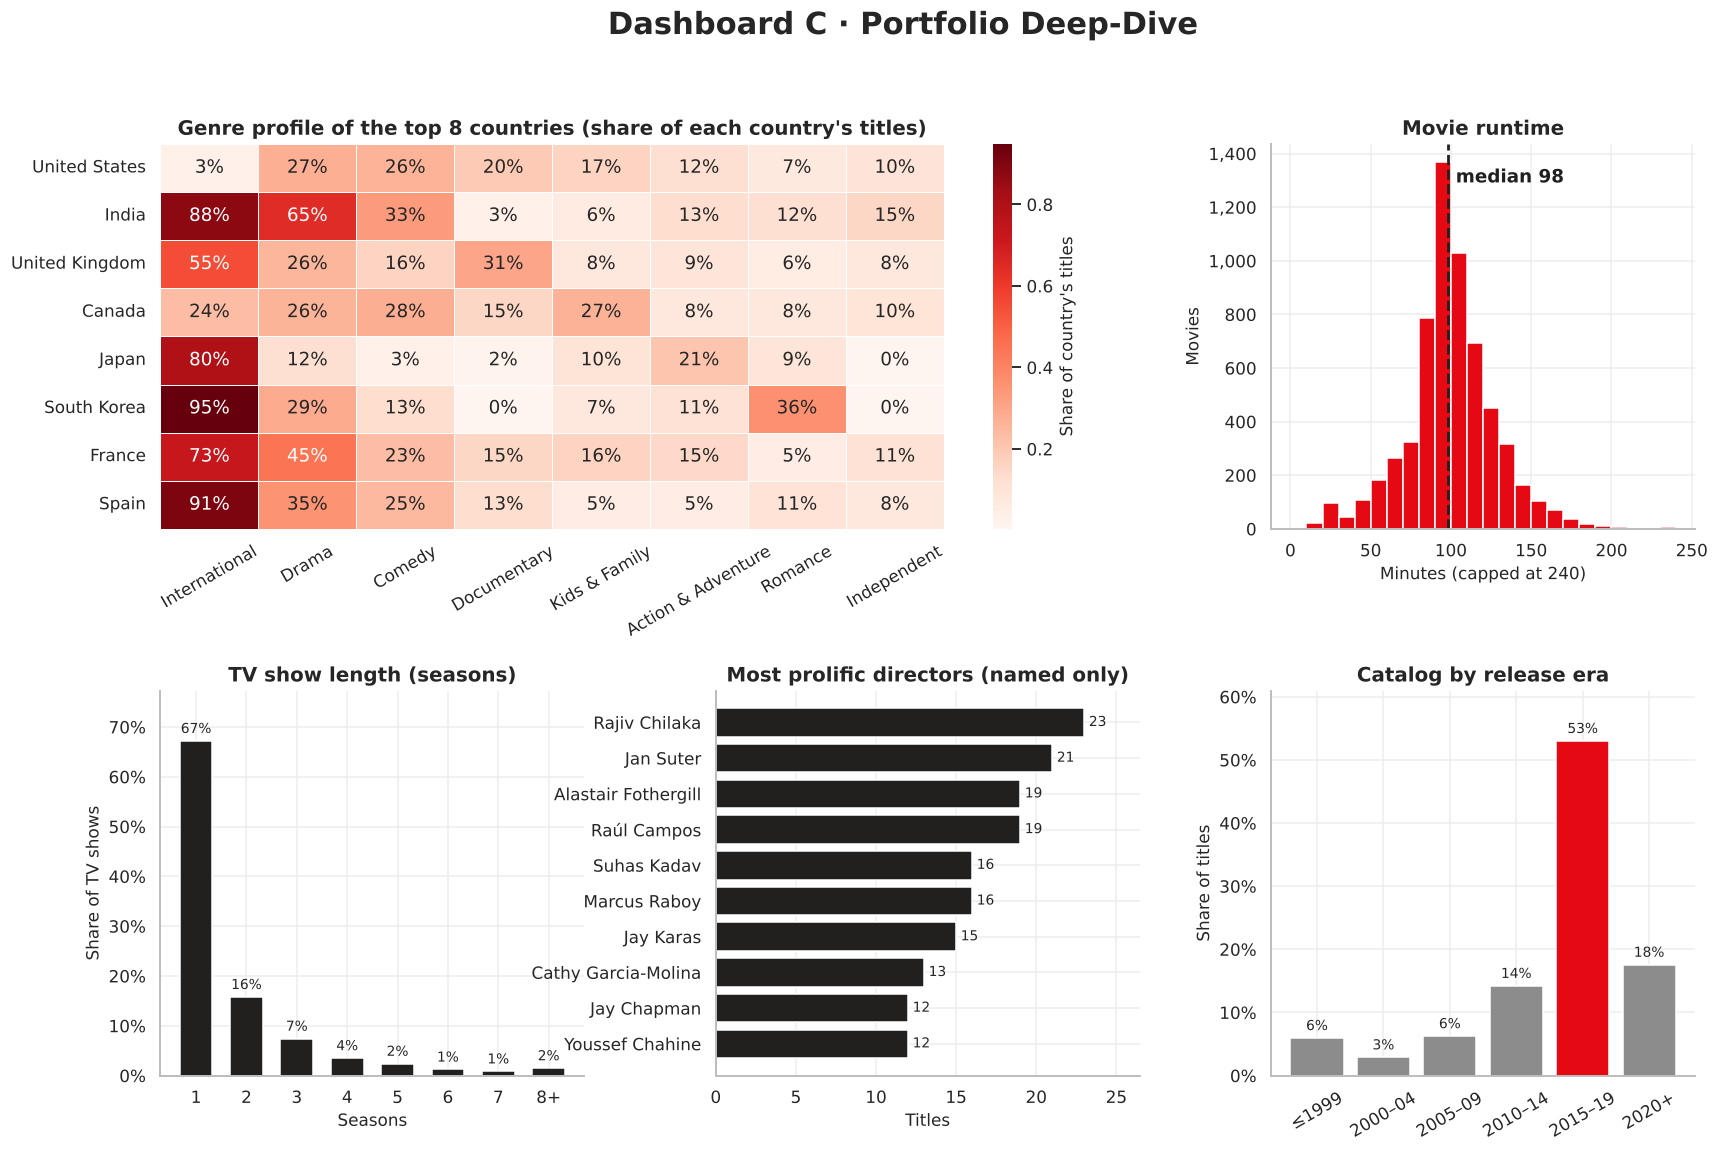

In [68]:
# ---------------------------------- Dashboard C: Portfolio deep-dive ----------------------------------
fig = plt.figure(figsize=(18, 11))
gs = GridSpec(2, 6, figure=fig, hspace=0.42, wspace=0.9)
fig.suptitle("Dashboard C · Portfolio Deep-Dive", fontsize=20, fontweight="bold", y=0.99)

# (1) country x genre heat map
ax = fig.add_subplot(gs[0, 0:4])
cg = genre_u_main[genre_u_main["country_reliable"].isin(rank.head(8).index)]
cg_tbl = pd.crosstab(cg["country_reliable"], cg["genre"])
top_g8 = uni.head(8).index
cg_pct = cg_tbl[top_g8].div(df[df["country_reliable"].isin(rank.head(8).index)].groupby("country_reliable").size(), axis=0).loc[rank.head(8).index]
sns.heatmap(cg_pct, annot=True, fmt=".0%", cmap="Reds", linewidths=0.5, linecolor="white", cbar_kws={"label": "Share of country's titles"}, ax=ax)
ax.set(title="Genre profile of the top 8 countries (share of each country's titles)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=30)

# (2) movie runtime
ax = fig.add_subplot(gs[0, 4:6])
ax.hist(movies.clip(upper=240), bins=np.arange(0, 250, 10), color=RED, edgecolor="white")
ax.axvline(movies.median(), color=DARK, ls="--", lw=1.8)
ax.set(title="Movie runtime", xlabel="Minutes (capped at 240)", ylabel="Movies")
ax.text(movies.median() + 5, ax.get_ylim()[1] * 0.9, f"median {movies.median():.0f}", fontweight="bold", color=DARK)
thousands(ax)

# (3) seasons
ax = fig.add_subplot(gs[1, 0:2])
bars = ax.bar([str(i) if i < 8 else "8+" for i in season_share.index], season_share.values, color=DARK, width=0.65)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in season_share.values], padding=3, fontsize=9)
ax.set(title="TV show length (seasons)", xlabel="Seasons", ylabel="Share of TV shows", ylim=(0, season_share.max() * 1.15))
percent_axis(ax)

# (4) directors
ax = fig.add_subplot(gs[1, 2:4])
td = top_dir.iloc[::-1]
bars = ax.barh(td.index, td["titles"], color=DARK)
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(title="Most prolific directors (named only)", xlabel="Titles", xlim=(0, td["titles"].max() * 1.15))

# (5) release era
ax = fig.add_subplot(gs[1, 4:6])
era_counts = df["release_era"].value_counts().reindex(ERA_LABELS)
bars = ax.bar(ERA_LABELS, era_counts.values / len(df), color=[RED if v == era_counts.max() else GREY for v in era_counts.values])
ax.bar_label(bars, labels=[f"{v / len(df):.0%}" for v in era_counts.values], padding=3, fontsize=9)
ax.set(title="Catalog by release era", ylabel="Share of titles", ylim=(0, era_counts.max() / len(df) * 1.15))
ax.tick_params(axis="x", rotation=30)
percent_axis(ax)

save_fig(fig, "task6_dashboard_C_portfolio_deep_dive")
plt.show()

## Step 4 · Actionable business insights

Each insight links **evidence from the data** to a **recommended action** and a priority. Priorities are the analyst's judgement of business impact × confidence in the evidence; they are not outputs of a model.

In [69]:
n_artifacts = int(df["title_date_artifact"].sum())
dir_unknown_share = (df["director"] == "Unknown").mean()
non_us_first, non_us_last = by_year["non_us_share"].iloc[0], by_year["non_us_share"].iloc[-1]
non_us_word = trend_word(non_us_first, non_us_last, 0.05)
month_ratio = avg_month_share[top_months].mean() * 12
low_months = avg_month_share.sort_values().index[:3]

insights = pd.DataFrame([
    {"Theme": "Format mix",
     "Evidence": f"Movies are {movie_n / len(df):.0%} of the catalog, and TV's share of additions has stayed between {tv_lo:.0%} and {tv_hi:.0%} since 2017 ({tv_early:.0%} in 2016–18 vs {tv_late:.0%} in 2019–21). {season_share.get(1, 0):.0%} of series have a single season.",
     "Recommended action": "Keep movies for breadth and treat series as the lever for depth: prioritise series with renewal potential and track season-to-season retention as a KPI (not available in this dataset).",
     "Priority": "High"},
    {"Theme": "Geographic strategy",
     "Evidence": f"{rank.index[0]} supplies {us_share:.0%} of titles with a known country and the top 5 countries supply {top5_share:.0%}. The non-US share of additions {non_us_word} ({non_us_first:.0%} → {non_us_last:.0%}), but the mix within it is moving: gaining share — {', '.join(c_mom.tail(3).iloc[::-1].index)}; losing — {', '.join(c_mom.head(3).index)}.",
     "Recommended action": "Treat the non-US share as a stable base and manage the mix inside it: investigate why some large markets are losing share and test export of high-TV-share markets (e.g. South Korea, Japan) as global series.",
     "Priority": "High"},
    {"Theme": "Volume cycle",
     "Evidence": f"Releases peaked in {peak_year} ({peak_n:,} titles) and changed {post_peak_change:+.0%} by {LAST_FULL_YEAR}; additions peaked in {add_peak_year} and were {add_last_full:,} in {LAST_FULL_YEAR}.",
     "Recommended action": "Move headline KPIs from titles added to engagement per title. Avoid re-expanding volume without evidence of viewing demand.",
     "Priority": "Medium"},
    {"Theme": "Audience coverage",
     "Evidence": f"{adult_share_all + teen_share_all:.0%} of titles are rated for teens or adults; kids / all-ages is {kids_share_all:.0%} and concentrated in the Kids & Family genre.",
     "Recommended action": "Evaluate a targeted kids & family expansion if household growth is a goal; otherwise keep the adult-skewed positioning deliberate and consistent.",
     "Priority": "Medium"},
    {"Theme": "Genre momentum",
     "Evidence": f"Gaining share: {', '.join(gainers.index[:3])} ({', '.join(f'{v:+.1f} pp' for v in gainers.values[:3])}). Losing share: {', '.join(losers.index[:3])} ({', '.join(f'{v:+.1f} pp' for v in losers.values[:3])}).",
     "Recommended action": "Prioritise development slates in gaining genres; review losing genres for deliberate de-prioritisation versus unintended gaps.",
     "Priority": "Medium"},
    {"Theme": "Content freshness",
     "Evidence": f"Back-catalog titles ({BACKCATALOG_YEARS}+ years old) are {by_year['backcatalog'].iloc[-1]:.0%} of {by_year.index[-1]} additions versus {by_year['backcatalog'].iloc[0]:.0%} in {by_year.index[0]}.",
     "Recommended action": "Decide explicitly what role older titles play (retention vs acquisition) and surface them through recommendations rather than only new releases.",
     "Priority": "Low"},
    {"Theme": "Release calendar",
     "Evidence": f"{', '.join(calendar.month_name[m] for m in top_months)} receive about {month_ratio:.2f}× an even share of annual additions; {', '.join(calendar.month_name[m] for m in low_months)} are the quietest.",
     "Recommended action": "Align marketing and tentpole launches with the busiest months and use the quieter months to reduce churn gaps with scheduled releases.",
     "Priority": "Medium"},
    {"Theme": "Data governance",
     "Evidence": f"{dir_unknown_share:.0%} of directors are unknown; {int(df['country_suspect'].sum())} country labels look auto-filled; {n_dups} duplicate titles and {n_artifacts} spreadsheet-corrupted titles were found.",
     "Recommended action": "Add validation at ingestion (controlled country list, required fields, duplicate keys, text-typed titles). Fix source tagging before decisions rely on country-level analysis.",
     "Priority": "High"},
])

PRIORITY_COLORS = {"High": "#E50914", "Medium": "#F4A261", "Low": "#8C8C8C"}
display(
    insights.style.hide(axis="index")
    .set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top", "font-size": "13px"})
    .set_properties(subset=["Theme"], **{"font-weight": "bold", "min-width": "120px"})
    .set_properties(subset=["Evidence", "Recommended action"], **{"min-width": "340px"})
    .map(lambda v: f"color:white;font-weight:bold;background-color:{PRIORITY_COLORS.get(v, 'white')};text-align:center", subset=["Priority"])
    .set_caption("Insight → evidence → action")
)

Theme,Evidence,Recommended action,Priority
Format mix,"Movies are 70% of the catalog, and TV's share of additions has stayed between 25% and 34% since 2017 (29% in 2016–18 vs 31% in 2019–21). 67% of series have a single season.",Keep movies for breadth and treat series as the lever for depth: prioritise series with renewal potential and track season-to-season retention as a KPI (not available in this dataset).,High
Geographic strategy,"United States supplies 40% of titles with a known country and the top 5 countries supply 67%. The non-US share of additions held steady (56% → 54%), but the mix within it is moving: gaining share — United States, Japan, South Korea; losing — India, United Kingdom, Canada.","Treat the non-US share as a stable base and manage the mix inside it: investigate why some large markets are losing share and test export of high-TV-share markets (e.g. South Korea, Japan) as global series.",High
Volume cycle,"Releases peaked in 2018 (1,144 titles) and changed -17% by 2020; additions peaked in 2019 and were 1,879 in 2020.",Move headline KPIs from titles added to engagement per title. Avoid re-expanding volume without evidence of viewing demand.,Medium
Audience coverage,76% of titles are rated for teens or adults; kids / all-ages is 10% and concentrated in the Kids & Family genre.,Evaluate a targeted kids & family expansion if household growth is a goal; otherwise keep the adult-skewed positioning deliberate and consistent.,Medium
Genre momentum,"Gaining share: Comedy, Kids & Family, Action & Adventure (+5.5 pp, +3.3 pp, +2.5 pp). Losing share: Documentary, International, Stand-Up & Talk (-6.1 pp, -6.0 pp, -3.9 pp).",Prioritise development slates in gaining genres; review losing genres for deliberate de-prioritisation versus unintended gaps.,Medium
Content freshness,Back-catalog titles (5+ years old) are 35% of 2021 additions versus 19% in 2016.,Decide explicitly what role older titles play (retention vs acquisition) and surface them through recommendations rather than only new releases.,Low
Release calendar,"December, October, November receive about 1.31× an even share of annual additions; February, May, June are the quietest.",Align marketing and tentpole launches with the busiest months and use the quieter months to reduce churn gaps with scheduled releases.,Medium
Data governance,29% of directors are unknown; 401 country labels look auto-filled; 4 duplicate titles and 4 spreadsheet-corrupted titles were found.,"Add validation at ingestion (controlled country list, required fields, duplicate keys, text-typed titles). Fix source tagging before decisions rely on country-level analysis.",High


## Step 5 · Final analytical report

In [70]:
exec_summary = f"""
# Netflix Content Analytics — Executive Summary

**Scope.** {len(df):,} titles (**{movie_n:,} movies, {tv_n:,} TV shows**) added to Netflix between {df['date_added'].min():%B %Y} and {LAST_DATE:%B %Y}, released between {df['release_year'].min()} and {df['release_year'].max()}. Raw data of {len(df_raw):,} records was cleaned and validated (Task 1).

## Headline findings

1. **The catalog is movie-led, with a stable TV minority.** Movies are {movie_n / len(df):.0%} of titles; TV's share of new additions has stayed in a {tv_lo:.0%}–{tv_hi:.0%} band since 2017, and {season_share.get(1, 0):.0%} of series have only one season. TV is a larger share of recent releases ({era_share.iloc[-1]['TV Show']:.0%} of titles released from 2020).
2. **Supply is concentrated in a few countries.** {rank.index[0]} provides {us_share:.0%} of titles and the top 5 countries {top5_share:.0%}; the non-US share of new additions is stable ({non_us_first:.0%} in {by_year.index[0]}, {non_us_last:.0%} in {by_year.index[-1]}), with the mix shifting from {', '.join(c_mom.head(2).index)} towards {', '.join(c_mom.tail(2).iloc[::-1].index)}.
3. **Production peaked and the catalog is maturing.** Releases peaked in {peak_year} ({peak_n:,}); additions peaked in {add_peak_year} ({add_peak_n:,}). Back-catalog titles are now {by_year['backcatalog'].iloc[-1]:.0%} of additions.
4. **The catalog serves teens and adults.** {adult_share_all:.0%} of titles are adult-rated and {teen_share_all:.0%} teen-rated; kids / all-ages content is {kids_share_all:.0%}. {top_rating} is the largest rating.
5. **International content is mainstream.** The "International" genre appears on {uni['International'] / len(df):.0%} of titles; the most common genre pair is {top_pair['Genre A']} + {top_pair['Genre B']}.
6. **Additions are seasonal.** {', '.join(calendar.month_name[m] for m in top_months)} carry about {month_ratio:.2f}× an even share of yearly additions.

## Recommendations

* Use **series with renewal potential** as the lever for depth while protecting movie breadth.
* **Manage the non-US supply mix**: understand why some large markets are losing share and test exporting high-TV-share markets.
* Manage the catalog on **engagement per title**, not volume.
* Decide deliberately whether to **expand kids and family content**.
* **Fix data governance** (country tagging, missing directors, duplicate keys) before further country-level decisions.

## Limitations

* The dataset describes **catalog availability only** — no viewing, revenue, cost or subscriber data — so findings describe *what is offered*, not *what performs*.
* Each title carries a **single country** and the country tag is unreliable for {int(df['country_suspect'].sum())} records ({df['country_suspect'].mean():.1%}) and missing for {n_unknown} more.
* {PARTIAL_YEAR} is a **partial year** (data to {LAST_DATE:%d %B %Y}).
* Ratings follow the US system and genres are Netflix's own tags; comparisons are **associations, not causal claims**.

## Suggested next steps

1. Join viewing / engagement data to move from catalog analytics to performance analytics.
2. Build a recurring pipeline with automated validation (the Task 1 checks) and publish a BI dashboard (Power BI / Tableau / Streamlit).
3. Model title-level drivers of availability by country and genre once additional features are available.
"""
md(exec_summary)


# Netflix Content Analytics — Executive Summary

**Scope.** 8,786 titles (**6,123 movies, 2,663 TV shows**) added to Netflix between January 2008 and September 2021, released between 1925 and 2021. Raw data of 8,790 records was cleaned and validated (Task 1).

## Headline findings

1. **The catalog is movie-led, with a stable TV minority.** Movies are 70% of titles; TV's share of new additions has stayed in a 25%–34% band since 2017, and 67% of series have only one season. TV is a larger share of recent releases (49% of titles released from 2020).
2. **Supply is concentrated in a few countries.** United States provides 40% of titles and the top 5 countries 67%; the non-US share of new additions is stable (56% in 2016, 54% in 2021), with the mix shifting from India, United Kingdom towards United States, Japan.
3. **Production peaked and the catalog is maturing.** Releases peaked in 2018 (1,144); additions peaked in 2019 (2,013). Back-catalog titles are now 35% of additions.
4. **The catalog serves teens and adults.** 46% of titles are adult-rated and 30% teen-rated; kids / all-ages content is 10%. TV-MA is the largest rating.
5. **International content is mainstream.** The "International" genre appears on 49% of titles; the most common genre pair is International + Drama.
6. **Additions are seasonal.** December, October, November carry about 1.31× an even share of yearly additions.

## Recommendations

* Use **series with renewal potential** as the lever for depth while protecting movie breadth.
* **Manage the non-US supply mix**: understand why some large markets are losing share and test exporting high-TV-share markets.
* Manage the catalog on **engagement per title**, not volume.
* Decide deliberately whether to **expand kids and family content**.
* **Fix data governance** (country tagging, missing directors, duplicate keys) before further country-level decisions.

## Limitations

* The dataset describes **catalog availability only** — no viewing, revenue, cost or subscriber data — so findings describe *what is offered*, not *what performs*.
* Each title carries a **single country** and the country tag is unreliable for 401 records (4.6%) and missing for 287 more.
* 2021 is a **partial year** (data to 25 September 2021).
* Ratings follow the US system and genres are Netflix's own tags; comparisons are **associations, not causal claims**.

## Suggested next steps

1. Join viewing / engagement data to move from catalog analytics to performance analytics.
2. Build a recurring pipeline with automated validation (the Task 1 checks) and publish a BI dashboard (Power BI / Tableau / Streamlit).
3. Model title-level drivers of availability by country and genre once additional features are available.


In [71]:
# Persist report artefacts --------------------------------------------------------------------------------
(OUTPUT_DIR / "executive_summary.md").write_text(exec_summary.strip() + "\n", encoding="utf-8")
insights.to_csv(OUTPUT_DIR / "business_insights.csv", index=False)
by_year.to_csv(OUTPUT_DIR / "yearly_scorecard.csv")
rank.to_csv(OUTPUT_DIR / "country_ranking.csv")
log_df.to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)

produced = sorted(p for p in OUTPUT_DIR.rglob("*") if p.is_file())
print(f"{len(produced)} output files in '{OUTPUT_DIR}/':")
for p in produced:
    print(f"  {str(p):<62}{p.stat().st_size / 1024:>8,.0f} KB")

24 output files in 'outputs/':
  outputs/business_insights.csv                                        3 KB
  outputs/cleaning_log.csv                                             1 KB
  outputs/country_ranking.csv                                          7 KB
  outputs/executive_summary.md                                         3 KB
  outputs/figures/task2_content_type_dashboard.png                   220 KB
  outputs/figures/task2_runtime_and_seasons.png                       99 KB
  outputs/figures/task2_tv_share_trend.png                            73 KB
  outputs/figures/task3_country_rankings.png                         178 KB
  outputs/figures/task3_pareto_and_continents.png                    176 KB
  outputs/figures/task3_tv_share_by_country.png                      125 KB
  outputs/figures/task4_release_trends.png                           149 KB
  outputs/figures/task4_seasonality_and_freshness.png                205 KB
  outputs/figures/task4_two_clocks_and_decades.png       

---

# Appendix

## A. Task completion checklist

| Task | Level | Completed | Where |
|------|-------|:---------:|-------|
| 1 · Data Cleaning & Preparation | Easy | ✔ | [Task 1](#task1) — cleaning log, 9 validation checks, `outputs/netflix_cleaned.csv` |
| 2 · Content Type Analysis Dashboard | Easy | ✔ | [Task 2](#task2) — dashboard, proportion comparison, significance test, summary |
| 3 · Country-Wise Content Analysis | Medium | ✔ | [Task 3](#task3) — rankings, concentration, sensitivity check, interactive map |
| 4 · Trend Analysis by Release Year | Medium | ✔ | [Task 4](#task4) — growth phases, CAGR, two-clock view, seasonality |
| 5 · Content Rating & Genre Analysis | Advanced | ✔ | [Task 5](#task5) — unified genre taxonomy, χ² / Mann–Whitney tests, 4 interactive charts |
| 6 · Business Insights Report | Advanced | ✔ | [Task 6](#task6) — EDA, 3 dashboards, insight table, executive summary |

## B. Skills demonstrated

* **Pandas:** type-safe loading, missing-value handling, de-duplication, `groupby`, `crosstab`, `explode`, reshaping, rolling windows, validated exports.
* **Data quality:** hidden-missing detection, false-positive handling, duplicate hidden by whitespace, spreadsheet-corruption detection, suspected-imputation detection.
* **Visualisation:** Matplotlib / Seaborn dashboards with consistent branding; Plotly sunburst, heat map, treemap, buttons and choropleth.
* **Statistics:** two-proportion z-test, χ² test with Cramér's V, Mann–Whitney U, CAGR, linear trend, Herfindahl–Hirschman index, lift.
* **Business communication:** insight → evidence → action framing, executive summary, explicit limitations.

## C. Submission checklist (per the programme guidelines)

- [x] Project source code — this notebook
- [x] Screenshots of completed tasks — `outputs/figures/*.png` (and the notebook outputs)
- [ ] GitHub repository link — push this notebook, `Dataset.csv` and the `outputs/` folder
- [ ] Demonstration video (optional)

## D. Reproducibility

Run **Kernel → Restart & Run All**. The notebook needs only `Dataset.csv` next to it; everything else is generated into `outputs/`.

In [72]:
import platform

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | matplotlib {plt.matplotlib.__version__} "
      f"| seaborn {sns.__version__} | scipy {stats.__name__ and __import__('scipy').__version__}")

Python 3.12.3 | pandas 3.0.6 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2 | scipy 1.18.1
